# Predictive Modeling: Feature Engineering

**Goal:** build one zip-month feature set for predicting food assistance (CalFresh dollars and food bank pounds) from LIHEAP enrollment, census demographics, time and policy context.

**Inputs** (all in the repository root):
- `TimeLag_PolicyAnnotated.csv`: LIHEAP enrollment with lags 1–3 and the policy annotations from Assignment 4
- `CalFresh_cleaned.csv`, `FoodBank_cleaned.csv`: outcomes, plus their history for year-over-year features
- `Demographics_SD_ZipCode.csv`: ACS 5-year census estimates by zip code

**Outputs:**
- `Predictive_Features.csv`: one row per zip-month with the targets and all features (missing values handled by the rules in Section 8)
- `Feature_Dictionary.csv`: each feature's group, rationale and missing-value rule

**Feature groups**
1. LIHEAP lag features (t-1, t-2, t-3)
2. Demographic indicators from census data
3. Temporal features (month, quarter, year-over-year change)
4. Policy change binary indicators (Assignment 4)
5. Interaction terms

In [1]:
import pandas as pd
import numpy as np

**Define Variables for the Key, LIHEAP WIndow and Demo Max Year**

In [2]:
KEY = ["Zip Code", "Month_Year"]
LIHEAP_WINDOW = ("2023-01", "2023-07")
DEMO_MAX_YEAR = 2023

**Load in Raw Data**

In [3]:
base = pd.read_csv("TimeLag_PolicyAnnotated.csv")
calfresh = pd.read_csv("CalFresh_cleaned.csv")
foodbank = pd.read_csv("FoodBank_cleaned.csv")
demo_raw = pd.read_csv("Demographics_SD_ZipCode.csv")

**Change Zip COde into integer**
**Define Period turning month year into month**

In [4]:
base["Zip Code"] = base["Zip Code"].astype(int)
base["Period"] = pd.PeriodIndex(base["Month_Year"], freq="M")

print(f"Base table: {base.shape[0]} zip-months, {base['Zip Code'].nunique()} zips, "
      f"{base['Month_Year'].min()} to {base['Month_Year'].max()}")

Base table: 852 zip-months, 121 zips, 2023-02 to 2023-10


In [5]:
base.head(5)

,Zip Code,Month_Year,Enrollment_Count,LIHEAP_lag1,LIHEAP_lag2,LIHEAP_lag3,lag1_status,lag2_status,lag3_status,Complete_Lags,...,CalFresh_Policy_Change,LIHEAP_Policy_Change,FoodBank_Policy_Change,Any_Policy_Change,Policy_Period_EA_Ended,Policy_Period_ABWD_Resumed,Policy_Period_LIHEAP_FY24_Cut,LIHEAP_Direction_Increased,LIHEAP_Direction_Decreased,Period
0,91901,2023-03,2.0,1.0,NaN,NaN,present,zip_gap,before_start,False,...,0,0,0,0,0,0,0,1,0,2023-03
1,91901,2023-04,1.0,2.0,1.0,NaN,present,present,zip_gap,False,...,1,0,1,1,1,0,0,1,0,2023-04
2,91901,2023-05,2.0,1.0,2.0,1.0,present,present,present,True,...,0,0,0,0,1,0,0,1,0,2023-05
3,91901,2023-06,2.0,2.0,1.0,2.0,present,present,present,True,...,0,0,0,0,1,0,0,1,0,2023-06
4,91901,2023-07,1.0,2.0,2.0,1.0,present,present,present,True,...,1,0,1,1,1,1,0,1,0,2023-07


## 2. Targets and outcome history

CalFresh dollars and food bank pounds are summed to one value per zip-month. Food bank months with zero pounds are treated as missing (no distribution recorded), matching `Correlation_Analysis.ipynb`. The full history (CalFresh from 2020, food bank from 2018) is kept so year-over-year features can look back 12–13 months.

In [6]:
cf_hist = (calfresh.groupby(["Zip Code", "Month Year"], as_index=False)["Calfresh Dollars"].sum()
          .rename(columns={"Month Year": "Month_Year", "Calfresh Dollars": "CalFresh_Dollars"}))

fb_hist = (foodbank.groupby(["Zip Code", "Month Year"], as_index=False)["Pounds_Distributed"].sum()
          .rename(columns={"Month Year": "Month_Year", "Pounds_Distributed": "FoodBank_Pounds"}))

fb_hist.loc[fb_hist["FoodBank_Pounds"]==0, "FoodBank_Pounds"] = np.nan

In [7]:
for h in (cf_hist, fb_hist):
    h["Zip Code"] = h["Zip Code"].astype(int)
    h["Period"] = pd.PeriodIndex(h["Month_Year"], freq="M")

df = (base.merge(cf_hist[["Zip Code", "Period", "CalFresh_Dollars"]], on=["Zip Code", "Period"], how="left")
     .merge(fb_hist[["Zip Code", "Period", "FoodBank_Pounds"]], on=["Zip Code", "Period"], how="left"))
assert len(df) == len(base)

TARGETS = ["CalFresh_Dollars", "FoodBank_Pounds"]
df[TARGETS].describe().T

,count,mean,std,min,25%,50%,75%,max
CalFresh_Dollars,850.0,750573.941000,841648.763015,3470.0,151896.365,489653.000,920151.250,4724991.000
FoodBank_Pounds,681.0,82382.303698,111292.856853,424.0,16186.000,47236.391,104791.702,776447.031


## 3. LIHEAP lag features (t-1, t-2, t-3)

**Rationale:** LIHEAP enrollment signals household energy hardship, which can precede food assistance demand by one to three months. The correlation analysis found the same-month and one-month lags most informative within zip codes, so all three lags are kept for the model to weigh.

**Missing values.** The `lagk_status` columns from `TimeLag_Generation.ipynb` say *why* a lag is empty, and the two cases are handled differently:
- `zip_gap`: the month is inside the LIHEAP data window but the zip had no enrollment record, so it is a true zero → set to **0**.
- `before_start` / `after_end`: the month falls outside the window (Jan–Jul 2023), so the value is unknown → left **missing**, with a `_observed` flag (1 = value known).

Two summary features are added: the 3-month mean of available lags (smooths noisy monthly counts) and the lag-1 minus lag-2 change (short-term momentum).

In [8]:
LAGS = {1: "LIHEAP_lag1", 2: "LIHEAP_lag2", 3: "LIHEAP_lag3"}

for k, col in LAGS.items():
    status = df[f"lag{k}_status"]
    df.loc[status == "zip_gap", col] = 0.0
    df.loc[status.isin(["before_start", "after_end"]), col] = np.nan
    df[f"{col}_observed"] = status.isin(["present", "zip_gap"]).astype(int)

in_window = df["Month_Year"].between(*LIHEAP_WINDOW)
df["LIHEAP_t0"] = np.where(in_window, df["Enrollment_Count"].fillna(0), np.nan)
df["LIHEAP_t0_observed"] = in_window.astype(int)

df["LIHEAP_lag_mean_3"] = df[list(LAGS.values())].mean(axis=1, skipna=True)
df["LIHEAP_lag_momentum"] = df["LIHEAP_lag1"] - df["LIHEAP_lag2"]

LAG_FEATURES = (["LIHEAP_t0"] + list(LAGS.values()) + ["LIHEAP_lag_mean_3", "LIHEAP_lag_momentum"]
               + ["LIHEAP_t0_observed"] + [f"{c}_observed" for c in LAGS.values()])
df[LAG_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
LIHEAP_t0,589.0,7.509338,10.001802,0.000000,1.0,5.0,11.000000,75.000000
LIHEAP_lag1,687.0,7.247453,9.527460,0.000000,1.0,5.0,10.000000,75.000000
LIHEAP_lag2,698.0,7.133238,9.495042,0.000000,1.0,4.0,10.000000,75.000000
LIHEAP_lag3,679.0,7.332842,9.550732,0.000000,1.0,5.0,10.000000,75.000000
LIHEAP_lag_mean_3,852.0,7.002543,8.534816,0.333333,1.0,5.0,9.333333,72.333333
LIHEAP_lag_momentum,609.0,-0.082102,5.440451,-36.000000,-2.0,0.0,2.000000,32.000000
LIHEAP_t0_observed,852.0,0.691315,0.462222,0.000000,0.0,1.0,1.000000,1.000000
LIHEAP_lag1_observed,852.0,0.806338,0.395399,0.000000,1.0,1.0,1.000000,1.000000
LIHEAP_lag2_observed,852.0,0.819249,0.385038,0.000000,1.0,1.0,1.000000,1.000000
LIHEAP_lag3_observed,852.0,0.796948,0.402507,0.000000,1.0,1.0,1.000000,1.000000


## 4. Demographic indicators (census)

**Rationale:** need for both energy and food assistance tracks poverty, unemployment, housing costs and household makeup. The demographic analysis also found that the LIHEAP–food bank relationship depends strongly on poverty.

- One ACS vintage per zip code: the latest year up to 2023 with complete subject-table data, so no future information is used.
- Counts are converted to **rates** (shares of population or households). Raw counts would mostly measure zip size, which the correlation analysis showed inflates relationships.
- `Log_Households` is kept as an explicit size control, and LIHEAP is also expressed per 1,000 households.

**Missing values:** zips with no ACS match (mostly PO-box zips) get the median across zip codes for each indicator, plus a `Demo_Imputed` flag so the model can tell imputed rows apart.

In [9]:
demo = (demo_raw[(demo_raw["Data_Year"] <= DEMO_MAX_YEAR)
    & (~demo_raw["Has_Missing_Demographic_Data"].astype(bool))]
        .sort_values("Data_Year")
        .groupby("Zip Code", as_index=False).tail(1)
        .copy())

demo["Zip Code"] = demo["Zip Code"].astype(int)

pop = demo["Total_Population"].replace(0, np.nan)
hh = demo["Total_Households"].replace(0, np.nan)

demo = demo.assign(
    Poverty_Rate=demo["Poverty_Rate_Pct"],
    Unemployment_Rate=demo["Unemployment_Rate_Pct"],
    Median_Rent_k = demo["Median_Gross_Rent"] / 1000,
    Pct_Under_18 = demo["Population_Under_18"] / pop * 100,
    Pct_65_Plus = demo["Population_65_Plus"] / pop * 100,
    Pct_Single_Parent_HH = (demo["Single_Father_Households_With_Own_Children_Under18"]
                           + demo["Single_Mother_Households_With_Own_Children_Under18"]) / hh * 100,
    Pct_Living_Alone = demo["Householder_Living_Alone"] / hh * 100,
    Avg_HH_Size = pop / hh,
    Log_Households = np.log1p(demo["Total_Households"]),
)

DEMO_FEATURES = ["Poverty_Rate", "Unemployment_Rate", "Median_Rent_k", "Pct_Under_18", "Pct_65_Plus",
                "Pct_Single_Parent_HH", "Pct_Living_Alone", "Avg_HH_Size", "Log_Households"]

df = df.merge(demo[["Zip Code", "Total_Households"] + DEMO_FEATURES], on="Zip Code",
             how="left", validate="many_to_one")

df["Demo_Imputed"] = df["Poverty_Rate"].isna().astype(int)
zip_medians = demo[DEMO_FEATURES].median()
df[DEMO_FEATURES] = df[DEMO_FEATURES].fillna(zip_medians)

df["LIHEAP_lag1_per_1k_HH"] = df["LIHEAP_lag1"] / df["Total_Households"] * 1000

print(f"Zips without census data (median-imputed): "
      f"{df.loc[df['Demo_Imputed'] == 1, 'Zip Code'].nunique()} of {df['Zip Code'].nunique()}")
df[DEMO_FEATURES].describe().T

Zips without census data (median-imputed): 32 of 121


,count,mean,std,min,25%,50%,75%,max
Poverty_Rate,852.0,10.152582,4.306905,2.900000,7.400000,9.600000,11.800000,21.800000
Unemployment_Rate,852.0,5.814906,1.889976,0.000000,4.700000,5.400000,6.600000,12.400000
Median_Rent_k,852.0,2.208011,0.457233,0.986000,1.912500,2.143000,2.462000,3.501000
Pct_Under_18,852.0,21.215012,4.823077,4.189938,19.074262,21.954901,23.901734,33.128025
Pct_65_Plus,852.0,16.180062,5.113849,6.676289,13.447274,16.172952,17.863388,42.531250
Pct_Single_Parent_HH,852.0,7.021860,2.788577,1.275046,5.509804,6.340013,8.634021,15.786372
Pct_Living_Alone,852.0,23.265146,8.345664,9.971510,18.328680,22.027990,25.693939,59.215208
Avg_HH_Size,852.0,2.826648,0.403919,1.679909,2.643345,2.821796,3.070305,3.613039
Log_Households,852.0,9.316017,0.866640,5.707110,9.258654,9.481893,9.811382,10.263641


## 5. Temporal features (month, quarter, year-over-year change)

**Rationale:** food assistance has seasonal patterns (for example holiday-season food bank demand), and 2023 included program-wide shifts.
- `Month`, `Quarter`: calendar seasonality. `Month_sin` and `Month_cos` encode month as a cycle, so December and January sit next to each other.
- `Months_Since_Start`: linear trend across the study window.
- **Year-over-year change** uses only *past* outcome values, so the target never leaks into its own features:
  - `*_lag1`: last month's value (autoregressive baseline)
  - `*_same_month_last_year`: value 12 months earlier (seasonal baseline)
  - `*_yoy_change_lag1`: last month vs. the same month a year before, (t-1 ÷ t-13) − 1

**Missing values:** history features are missing when the zip had no record at that earlier month. They are left missing here; Section 8 fills them with 0 and adds a flag.

In [10]:
df["Month"] = df["Period"].dt.month
df["Quarter"] = df["Period"].dt.quarter
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)
df["Months_Since_Start"] = (df["Period"] - df["Period"].min()).apply(lambda x: x.n)

In [11]:
def lagged_value(df, hist, value_col, k, new_col):
    h = hist[["Zip Code", "Period", value_col]].copy()
    h["Period"] = h["Period"] + k
    return df.merge(h.rename(columns={value_col: new_col}), on=["Zip Code", "Period"], how="left")

for hist, col, short in [(cf_hist, "CalFresh_Dollars", "CalFresh"),
                         (fb_hist, "FoodBank_Pounds", "FoodBank")]:
    df = lagged_value(df, hist, col, 1, f"{short}_lag1")
    df = lagged_value(df, hist, col, 12, f"{short}_same_month_last_year")
    df = lagged_value(df, hist, col, 13, f"_{short}_lag13")
    df[f"{short}_yoy_change_lag1"] = df[f"{short}_lag1"] / df[f"_{short}_lag13"] - 1
    df = df.drop(columns=f"_{short}_lag13")

df = df.replace([np.inf, -np.inf], np.nan)

TEMPORAL_FEATURES = ["Month", "Quarter", "Month_sin", "Month_cos", "Months_Since_Start",
                     "CalFresh_lag1", "CalFresh_same_month_last_year", "CalFresh_yoy_change_lag1",
                     "FoodBank_lag1", "FoodBank_same_month_last_year", "FoodBank_yoy_change_lag1"]
df[TEMPORAL_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Month,852.0,5.964789,2.454987e+00,2.000000,4.000000,6.000000e+00,8.000000e+00,1.000000e+01
Quarter,852.0,2.320423,8.962152e-01,1.000000,2.000000,2.000000e+00,3.000000e+00,4.000000e+00
Month_sin,852.0,0.010794,7.679698e-01,-1.000000,-0.866025,1.224647e-16,8.660254e-01,1.000000e+00
Month_cos,852.0,-0.362518,5.288734e-01,-1.000000,-0.866025,-5.000000e-01,6.123234e-17,5.000000e-01
Months_Since_Start,852.0,3.964789,2.454987e+00,0.000000,2.000000,4.000000e+00,6.000000e+00,8.000000e+00
CalFresh_lag1,850.0,788972.520976,8.890791e+05,3470.000000,162288.760000,5.151644e+05,9.751370e+05,4.724991e+06
CalFresh_same_month_last_year,851.0,957581.584019,1.033254e+06,3970.000000,201691.500000,6.227940e+05,1.231192e+06,4.742697e+06
CalFresh_yoy_change_lag1,849.0,-0.155240,2.335203e-01,-0.582186,-0.327886,-2.752665e-01,1.038727e-01,5.342917e-01
FoodBank_lag1,680.0,82934.751623,1.115224e+05,424.000000,16207.000000,4.797394e+04,1.048189e+05,7.764470e+05
FoodBank_same_month_last_year,672.0,89821.509032,1.232887e+05,340.000000,18374.867500,4.899248e+04,1.152191e+05,9.099421e+05


## 6. Policy change binary indicators (Assignment 4)

**Rationale:** 2023 included the end of CalFresh Emergency Allotments (April), ABAWD work rules resuming (July) and a LIHEAP FY24 funding cut (October). These can shift assistance levels independently of need. The indicators come straight from the Assignment 4 policy annotations in `TimeLag_PolicyAnnotated.csv`.

- `*_Policy_Active` columns are converted from Yes/No to 1/0.
- Columns that never vary in this window (every month is "active") carry no information and are dropped.

**Missing values:** none. Policy status is defined for every month.

In [12]:
POLICY_CANDIDATES = ["CalFresh_Policy_Active", "LIHEAP_Policy_Active", "FoodBank_Policy_Active",
                    "Any_Policy_Active", "CalFresh_Policy_Change", "LIHEAP_Policy_Change",
                    "FoodBank_Policy_Change", "Any_Policy_Change", "Policy_Period_EA_Ended",
                    "Policy_Period_ABWD_Resumed", "Policy_Period_LIHEAP_FY24_Cut",
                    "LIHEAP_Direction_Increased", "LIHEAP_Direction_Decreased"]

for c in POLICY_CANDIDATES:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].map({"Yes": 1, "No": 0})
    df[c] = df[c].fillna(0).astype(int)

constant = [c for c in POLICY_CANDIDATES if df[c].nunique() == 1]
POLICY_FEATURES = [c for c in POLICY_CANDIDATES if c not in constant]
print("Dropped (no variation in this window):", constant)

df.groupby("Month_Year")[POLICY_FEATURES].first()

Dropped (no variation in this window): ['CalFresh_Policy_Active', 'LIHEAP_Policy_Active', 'Any_Policy_Active']


,FoodBank_Policy_Active,CalFresh_Policy_Change,LIHEAP_Policy_Change,FoodBank_Policy_Change,Any_Policy_Change,Policy_Period_EA_Ended,Policy_Period_ABWD_Resumed,Policy_Period_LIHEAP_FY24_Cut,LIHEAP_Direction_Increased,LIHEAP_Direction_Decreased
Month_Year,,,,,,,,,,
2023-02,1,0,1,0,1,0,0,0,1,0
2023-03,1,0,0,0,0,0,0,0,1,0
2023-04,1,1,0,1,1,1,0,0,1,0
2023-05,1,0,0,0,0,1,0,0,1,0
2023-06,1,0,0,0,0,1,0,0,1,0
2023-07,1,1,0,1,1,1,1,0,1,0
2023-08,1,0,0,0,0,1,1,0,1,0
2023-09,1,1,0,0,1,1,1,0,1,0
2023-10,0,1,1,1,1,1,1,1,0,1


## 7. Interaction terms

**Rationale:** earlier analysis showed the LIHEAP–food bank link is strong in high-poverty zip codes and absent in low-poverty ones, so the effect of LIHEAP depends on context. Interaction terms let a linear model capture this.

| Interaction | Why |
|---|---|
| `LIHEAP_lag1 × Poverty_Rate` | LIHEAP signal stronger where poverty is high |
| `LIHEAP_lag1 × Unemployment_Rate` | energy hardship plus job loss compounds food need |
| `LIHEAP_lag1 × Median_Rent_k` | high housing cost leaves less for food |
| `LIHEAP_lag1 × Policy_Period_EA_Ended` | loss of Emergency Allotments may change how LIHEAP need translates to food demand |
| `LIHEAP_lag1_per_1k_HH × Poverty_Rate` | size-adjusted version of the poverty interaction |

Continuous moderators are **centered** at their median before multiplying. This reduces collinearity with the main effects, and the LIHEAP main effect can then be read as its effect at a typical zip.

In [13]:
center = lambda s: s - s.median()

df["LIHEAPxPoverty"] = df["LIHEAP_lag1"] * center(df["Poverty_Rate"])
df["LIHEAPxUnemployment"] = df["LIHEAP_lag1"] * center(df["Unemployment_Rate"])
df["LIHEAPxRent"] = df["LIHEAP_lag1"] * center(df["Median_Rent_k"])
df["LIHEAPxEA_Ended"] = df["LIHEAP_lag1"] * df["Policy_Period_EA_Ended"]
df["LIHEAPperHHxPoverty"] = df["LIHEAP_lag1_per_1k_HH"] * center(df["Poverty_Rate"])

INTERACTION_FEATURES = ["LIHEAPxPoverty", "LIHEAPxUnemployment", "LIHEAPxRent", "LIHEAPxEA_Ended", "LIHEAPperHHxPoverty"]
df[INTERACTION_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
LIHEAPxPoverty,687.0,19.534207,94.529082,-88.200000,-5.900000,0.0,11.250000,915.000000
LIHEAPxUnemployment,687.0,7.751674,23.110898,-31.900000,-1.650000,0.0,7.200000,163.200000
LIHEAPxRent,687.0,-0.330189,4.449438,-34.200000,-1.065500,0.0,0.933000,20.628000
LIHEAPxEA_Ended,687.0,5.435226,9.008650,0.000000,0.000000,1.0,8.000000,75.000000
LIHEAPperHHxPoverty,573.0,1.690021,6.561639,-6.563447,-0.748982,0.0,1.357356,74.786325


## 8. Consistent missing-value handling

One rule per type of missingness, applied the same way across all feature groups:

| Type | Example | Rule |
|---|---|---|
| Structural zero | LIHEAP `zip_gap` inside the data window | set to 0 (done in Section 3) |
| Outside data window | LIHEAP lags before Jan or after Jul 2023 | fill 0 **and** keep the `_observed` flag |
| No history | `*_lag1`, `*_same_month_last_year`, `*_yoy_change_lag1` | fill 0 **and** add a `_missing` flag |
| No census match | zips without ACS data | median across zips **and** `Demo_Imputed` flag (Section 4) |
| Derived from missing | interactions, per-household LIHEAP | fill 0 (the parent flags already mark these rows) |
| Target | `CalFresh_Dollars`, `FoodBank_Pounds` | **never imputed**; rows without a target are dropped at modeling time |

Filling with 0 *plus* a flag lets tree models and linear models both separate "zero" from "unknown". The table below shows missingness before and after.

In [14]:
FEATURES = LAG_FEATURES + DEMO_FEATURES + ["Demo_Imputed", "LIHEAP_lag1_per_1k_HH"] \
           + TEMPORAL_FEATURES + POLICY_FEATURES + INTERACTION_FEATURES

missing_before = df[FEATURES].isna().sum()

#handle based LIHEAP gaps 

for col in ["LIHEAP_t0"] + list(LAGS.values()):
    df[col] = df[col].fillna(0)
df["LIHEAP_lag_mean_3"] = df["LIHEAP_lag_mean_3"].fillna(0)
df["LIHEAP_lag_momentum"] = df["LIHEAP_lag_momentum"].fillna(0)

#history faetures >0 plus a missing flag 
HISTORY = ["CalFresh_lag1", "CalFresh_same_month_last_year", "CalFresh_yoy_change_lag1",
          "FoodBank_lag1", "FoodBank_same_month_last_year", "FoodBank_yoy_change_lag1"]

for col in HISTORY:
    df[f"{col}_missing"] = df[col].isna().astype(int)
    df[col] = df[col].fillna(0)
FEATURES += [f"{c}_missing" for c in HISTORY]

#derived features >- 0
for col in ["LIHEAP_lag1_per_1k_HH"] + INTERACTION_FEATURES:
    df[col] = df[col].fillna(0)

missing_after = df[FEATURES].isna().sum()
summary=pd.DataFrame({"missing_before": missing_before,
                     "missing_after": missing_after}).fillna(0).astype(int)
summary[summary["missing_before"] > 0]

,missing_before,missing_after
CalFresh_lag1,2,0
CalFresh_same_month_last_year,1,0
CalFresh_yoy_change_lag1,3,0
FoodBank_lag1,172,0
FoodBank_same_month_last_year,180,0
FoodBank_yoy_change_lag1,182,0
LIHEAP_lag1,165,0
LIHEAP_lag1_per_1k_HH,279,0
LIHEAP_lag2,154,0
LIHEAP_lag3,173,0


**Define the Feature Dictionary**

In [15]:
RATIONALE = {
    "LIHEAP_t0": ("LIHEAP lag", "Same-month enrollment; strongest within-zip link to CalFresh (r = 0.53)", "Outside window: 0 + flag"),
    "LIHEAP_lag1": ("LIHEAP lag", "Enrollment 1 month earlier; most useful leading indicator in the correlation analysis", "zip_gap: 0; outside window: 0 + flag"),
    "LIHEAP_lag2": ("LIHEAP lag", "Enrollment 2 months earlier; tests a longer lead time", "zip_gap: 0; outside window: 0 + flag"),
    "LIHEAP_lag3": ("LIHEAP lag", "Enrollment 3 months earlier; strongest cross-zip correlation with CalFresh (rho = 0.70)", "zip_gap: 0; outside window: 0 + flag"),
    "LIHEAP_lag_mean_3": ("LIHEAP lag", "Average of available lags; smooths noisy monthly counts", "Mean of available lags; 0 if none"),
    "LIHEAP_lag_momentum": ("LIHEAP lag", "Lag 1 minus lag 2; whether enrollment is rising or falling", "0 if either lag unknown"),
    "LIHEAP_t0_observed": ("LIHEAP lag", "1 if same-month LIHEAP is inside the data window", "None"),
    "LIHEAP_lag1_observed": ("LIHEAP lag", "1 if lag 1 is inside the data window", "None"),
    "LIHEAP_lag2_observed": ("LIHEAP lag", "1 if lag 2 is inside the data window", "None"),
    "LIHEAP_lag3_observed": ("LIHEAP lag", "1 if lag 3 is inside the data window", "None"),
    "Poverty_Rate": ("Demographic", "Core driver of need; moderates the LIHEAP-food bank link", "Median of zips + Demo_Imputed"),
    "Unemployment_Rate": ("Demographic", "Job loss raises demand for both programs", "Median of zips + Demo_Imputed"),
    "Median_Rent_k": ("Demographic", "Housing cost burden (thousands of $); weaker LIHEAP-food bank link in high-rent zips", "Median of zips + Demo_Imputed"),
    "Pct_Under_18": ("Demographic", "Households with children are prioritized by food programs", "Median of zips + Demo_Imputed"),
    "Pct_65_Plus": ("Demographic", "Older residents use programs differently (fixed incomes, lower CalFresh uptake)", "Median of zips + Demo_Imputed"),
    "Pct_Single_Parent_HH": ("Demographic", "Single-parent households face higher food insecurity", "Median of zips + Demo_Imputed"),
    "Pct_Living_Alone": ("Demographic", "Single-person households have different assistance patterns", "Median of zips + Demo_Imputed"),
    "Avg_HH_Size": ("Demographic", "Larger households need more food per enrollee", "Median of zips + Demo_Imputed"),
    "Log_Households": ("Demographic", "Controls for zip size, which inflates raw-total correlations", "Median of zips + Demo_Imputed"),
    "Demo_Imputed": ("Demographic", "1 if census values were median-imputed (no ACS match)", "None"),
    "LIHEAP_lag1_per_1k_HH": ("Demographic", "Size-adjusted LIHEAP; separates need from population", "0 if lag or households unknown"),
    "Month": ("Temporal", "Calendar month for seasonality", "None"),
    "Quarter": ("Temporal", "Quarter for broader seasonality", "None"),
    "Month_sin": ("Temporal", "Cyclical month encoding (December next to January)", "None"),
    "Month_cos": ("Temporal", "Cyclical month encoding (pair with Month_sin)", "None"),
    "Months_Since_Start": ("Temporal", "Linear trend across the study window", "None"),
    "CalFresh_lag1": ("Temporal", "Last month's CalFresh; strong persistence baseline", "0 + _missing flag"),
    "CalFresh_same_month_last_year": ("Temporal", "Seasonal baseline 12 months earlier", "0 + _missing flag"),
    "CalFresh_yoy_change_lag1": ("Temporal", "Year-over-year change using past values only (t-1 vs t-13)", "0 + _missing flag"),
    "FoodBank_lag1": ("Temporal", "Last month's food bank pounds; persistence baseline", "0 + _missing flag"),
    "FoodBank_same_month_last_year": ("Temporal", "Seasonal baseline 12 months earlier", "0 + _missing flag"),
    "FoodBank_yoy_change_lag1": ("Temporal", "Year-over-year change using past values only (t-1 vs t-13)", "0 + _missing flag"),
    "FoodBank_Policy_Active": ("Policy", "Any food bank policy in effect that month", "None"),
    "CalFresh_Policy_Change": ("Policy", "CalFresh policy changed that month", "None"),
    "LIHEAP_Policy_Change": ("Policy", "LIHEAP policy changed that month", "None"),
    "FoodBank_Policy_Change": ("Policy", "Food bank policy changed that month", "None"),
    "Any_Policy_Change": ("Policy", "Any program's policy changed that month", "None"),
    "Policy_Period_EA_Ended": ("Policy", "After CalFresh Emergency Allotments ended (Apr 2023)", "None"),
    "Policy_Period_ABWD_Resumed": ("Policy", "After ABAWD work rules resumed (Jul 2023)", "None"),
    "Policy_Period_LIHEAP_FY24_Cut": ("Policy", "After LIHEAP FY24 funding cut (Oct 2023)", "None"),
    "LIHEAP_Direction_Increased": ("Policy", "LIHEAP policy expected to raise enrollment", "None"),
    "LIHEAP_Direction_Decreased": ("Policy", "LIHEAP policy expected to lower enrollment", "None"),
    "LIHEAPxPoverty": ("Interaction", "LIHEAP effect stronger in high-poverty zips", "0 when lag 1 unknown"),
    "LIHEAPxUnemployment": ("Interaction", "Energy hardship plus job loss compounds food need", "0 when lag 1 unknown"),
    "LIHEAPxRent": ("Interaction", "High housing cost leaves less for food", "0 when lag 1 unknown"),
    "LIHEAPxEA_Ended": ("Interaction", "LIHEAP-food link may change after Emergency Allotments ended", "0 when lag 1 unknown"),
    "LIHEAPperHHxPoverty": ("Interaction", "Size-adjusted LIHEAP x poverty", "0 when inputs unknown"),
}

for col in HISTORY:
    RATIONALE[f"{col}_missing"] = ("Temporal", f"1 if {col} had no history and was filled with 0", "None")

feature_dict = pd.DataFrame(
    [(f, *RATIONALE.get(f, ("", "", ""))) for f in FEATURES],
    columns=["Feature", "Group", "Rationale", "Missing_value_rule"])
assert (feature_dict["Rationale"] != "").all(), "Every features needs a documented rationale"

print(f"{len(FEATURES)} features:", feature_dict["Group"].value_counts().to_dict())
feature_dict

53 features: {'Temporal': 17, 'Demographic': 11, 'LIHEAP lag': 10, 'Policy': 10, 'Interaction': 5}


,Feature,Group,Rationale,Missing_value_rule
0,LIHEAP_t0,LIHEAP lag,Same-month enrollment; strongest within-zip li...,Outside window: 0 + flag
1,LIHEAP_lag1,LIHEAP lag,Enrollment 1 month earlier; most useful leadin...,zip_gap: 0; outside window: 0 + flag
2,LIHEAP_lag2,LIHEAP lag,Enrollment 2 months earlier; tests a longer le...,zip_gap: 0; outside window: 0 + flag
3,LIHEAP_lag3,LIHEAP lag,Enrollment 3 months earlier; strongest cross-z...,zip_gap: 0; outside window: 0 + flag
4,LIHEAP_lag_mean_3,LIHEAP lag,Average of available lags; smooths noisy month...,Mean of available lags; 0 if none
5,LIHEAP_lag_momentum,LIHEAP lag,Lag 1 minus lag 2; whether enrollment is risin...,0 if either lag unknown
6,LIHEAP_t0_observed,LIHEAP lag,1 if same-month LIHEAP is inside the data window,None
7,LIHEAP_lag1_observed,LIHEAP lag,1 if lag 1 is inside the data window,None
8,LIHEAP_lag2_observed,LIHEAP lag,1 if lag 2 is inside the data window,None
9,LIHEAP_lag3_observed,LIHEAP lag,1 if lag 3 is inside the data window,None


**Save the Feature Set for Model Development**

In [16]:
out = df[KEY + TARGETS + FEATURES].sort_values(KEY).reset_index(drop=True)
out.to_csv("Predictive_Features.csv", index=False)
feature_dict.to_csv("Feature_Dictionary.csv", index=False)

print(f"Predictive_Features.csv: {out.shape[0]} rows x {out.shape[1]} columns")
print(f"Rows with a CalFresh target: {out['CalFresh_Dollars'].notna().sum()}; "
      f"with a food bank target: {out['FoodBank_Pounds'].notna().sum()}")
out.head()

Predictive_Features.csv: 852 rows x 57 columns
Rows with a CalFresh target: 850; with a food bank target: 681


,Zip Code,Month_Year,CalFresh_Dollars,FoodBank_Pounds,LIHEAP_t0,LIHEAP_lag1,LIHEAP_lag2,LIHEAP_lag3,LIHEAP_lag_mean_3,LIHEAP_lag_momentum,...,LIHEAPxUnemployment,LIHEAPxRent,LIHEAPxEA_Ended,LIHEAPperHHxPoverty,CalFresh_lag1_missing,CalFresh_same_month_last_year_missing,CalFresh_yoy_change_lag1_missing,FoodBank_lag1_missing,FoodBank_same_month_last_year_missing,FoodBank_yoy_change_lag1_missing
0,91901,2023-03,355789.00,51489.0,2.0,1.0,0.0,0.0,0.500000,1.0,...,0.0,-0.079,0.0,0.093956,0,0,0,0,0,0
1,91901,2023-04,230000.00,26145.0,1.0,2.0,1.0,0.0,1.000000,1.0,...,0.0,-0.158,2.0,0.187911,0,0,0,0,0,0
2,91901,2023-05,230786.00,27788.0,2.0,1.0,2.0,1.0,1.333333,-1.0,...,0.0,-0.079,1.0,0.093956,0,0,0,0,0,0
3,91901,2023-06,219267.00,17225.0,2.0,2.0,1.0,2.0,1.666667,1.0,...,0.0,-0.158,2.0,0.187911,0,0,0,0,0,0
4,91901,2023-07,207889.59,20383.0,1.0,2.0,2.0,1.0,1.666667,0.0,...,0.0,-0.158,2.0,0.187911,0,0,0,0,0,0


**Regression**

1. inputs: LIHEAP features, output: CalFresh Dollars
- linear regression model
- random forest regression model 
- 
2. inputs: LIHEAP features, output: FoodBank_Pounds  
- linear regression model 
- random forest regression model

In [17]:
feats = pd.read_csv("Predictive_Features.csv")

**Select the Libaries Required to Build a Regression Model**

In [77]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, HuberRegressor, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

**Setup Define this Once**

In [78]:
feats = pd.read_csv("Predictive_Features.csv")

CORE = ["LIHEAP_lag1", "LIHEAP_lag2", "LIHEAP_lag3", "LIHEAP_lag1_per_1k_HH",
        "Log_Households", "Poverty_Rate", "Unemployment_Rate", "Median_Rent_k", "Pct_65_Plus",
        "LIHEAPxPoverty", "LIHEAPxRent", "Demo_Imputed"]
HISTORY = {
    "CalFresh_Dollars": ["CalFresh_lag1", "CalFresh_yoy_change_lag1"],
    "FoodBank_Pounds": ["FoodBank_lag1", "FoodBank_yoy_change_lag1", "FoodBank_lag1_missing",
                        "Pct_Single_Parent_HH"],
}
POLICY = ["Policy_Period_EA_Ended", "LIHEAPxEA_Ended"]
BOOLEAN = ["Policy_Period_EA_Ended", "Demo_Imputed", "FoodBank_lag1_missing"]
LOG_DOLLARS = ["CalFresh_lag1", "FoodBank_lag1"]
TARGETS = ["CalFresh_Dollars", "FoodBank_Pounds"]
UNITS = {"CalFresh_Dollars": "$", "FoodBank_Pounds": "lb"}

# Policy events (for regime labels and plot markers)
POLICY_EVENTS = {"2023-04": "Emergency Allotments end", "2023-07": "ABAWD work rules resume"}


def regime(month):
    if month < "2023-04":
        return "Pre-EA end"
    if month == "2023-04":
        return "EA transition"
    if month < "2023-07":
        return "Post-EA"
    return "ABAWD resumed"


# Rows where LIHEAP lag 1 is observed (Feb-Aug 2023); hold out the most recent months
data = feats[feats["LIHEAP_lag1_observed"] == 1].copy()
TRAIN_END = "2023-06"     # train Feb-Jun (70%), test Jul-Aug (most recent period)
print(f"Train share: {(data['Month_Year'] <= TRAIN_END).mean():.0%} | "
      f"Test months: {sorted(data.loc[data['Month_Year'] > TRAIN_END, 'Month_Year'].unique())}")


def make_split(target, with_policy):
    rows = data.dropna(subset=[target])
    train = rows[rows["Month_Year"] <= TRAIN_END]
    test = rows[rows["Month_Year"] > TRAIN_END]
    features = CORE + HISTORY[target] + (POLICY if with_policy else [])
    features = [c for c in features if train[c].nunique() > 1]
    return train, test, features

Train share: 70% | Test months: ['2023-07', '2023-08']


**Perform Time Series Aware Cross Validation**

In [79]:
def time_folds(train, min_train_months=2):
    months = sorted(train["Month_Year"].unique())
    month_of_row = train["Month_Year"].values
    return [(np.where(np.isin(month_of_row, months[:i]))[0],
             np.where(month_of_row == months[i])[0])
            for i in range(min_train_months, len(months))]


def build_preprocessor(features):
    log_cols = [c for c in features if c in LOG_DOLLARS]
    bool_cols = [c for c in features if c in BOOLEAN]
    num_cols = [c for c in features if c not in log_cols + bool_cols]
    return ColumnTransformer(transformers=[
        ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())]), log_cols),
        ("num", StandardScaler(), num_cols),
        ("bool", "passthrough", bool_cols),
    ])


ALPHAS = np.logspace(-3, 3, 13)
MODEL_SPECS = {
    "Linear Regression": dict(
        make=lambda f: Pipeline([("preprocessor", build_preprocessor(f)), ("model", LinearRegression())]),
        grid=[{"model": [LinearRegression()], "model__fit_intercept": [True, False], "model__positive": [False, True]},
              {"model": [Ridge()], "model__alpha": ALPHAS},
              {"model": [Lasso(max_iter=20000)], "model__alpha": ALPHAS},
              {"model": [ElasticNet(max_iter=20000)], "model__alpha": ALPHAS, "model__l1_ratio": [0.2, 0.5, 0.8]},
              {"model": [HuberRegressor(max_iter=2000)], "model__epsilon": [1.1, 1.35, 1.75],
               "model__alpha": [0.0001, 0.01, 1.0]}],
        search="grid"),
    "Random Forest": dict(
        make=lambda f: Pipeline([("model", RandomForestRegressor(random_state=42, n_jobs=-1))]),
        grid={"model__n_estimators": [300, 600], "model__max_depth": [None, 8, 10, 15],
              "model__min_samples_leaf": [1, 2, 3, 5], "model__max_features": [0.4, 0.5, 0.7, 1.0],
              "model__max_samples": [0.7, None]},
        search="random", n_iter=25),
    "Hist Gradient Boosting": dict(
        make=lambda f: Pipeline([("model", HistGradientBoostingRegressor(early_stopping=False, random_state=42))]),
        grid={"model__loss": ["squared_error", "absolute_error"], "model__learning_rate": [0.02, 0.03, 0.05, 0.1],
              "model__max_iter": [200, 400, 800], "model__max_depth": [None, 3, 5],
              "model__max_leaf_nodes": [7, 15, 31], "model__min_samples_leaf": [5, 10, 20, 40],
              "model__l2_regularization": [0.0, 0.1, 1.0, 5.0]},
        search="random", n_iter=40),
}

In [95]:
def fit_and_evaluate(model_name, target, with_policy):
    spec = MODEL_SPECS[model_name]
    train, test, features = make_split(target, with_policy)
    X_train, X_test = train[features].astype(float), test[features].astype(float)
    y_train, y_test = np.log1p(train[target]), np.log1p(test[target])
    folds = time_folds(train)

    # Tune on time-aware folds
    if spec["search"] == "grid":
        search = GridSearchCV(spec["make"](features), spec["grid"], cv=folds,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        search = RandomizedSearchCV(spec["make"](features), spec["grid"], n_iter=spec["n_iter"], cv=folds,
                                    scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=42)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    version = "With policy" if with_policy else "Without policy"

    # Per-fold metrics with the chosen settings (refit on each fold's training months)
    fold_rows, oof = [], []
    for k, (tr, va) in enumerate(folds, start=1):
        m = spec["make"](features).set_params(**search.best_params_)
        m.fit(X_train.iloc[tr], y_train.iloc[tr])
        p_log = m.predict(X_train.iloc[va])
        a_log = y_train.iloc[va]
        month = train["Month_Year"].iloc[va].iloc[0]
        fold_rows.append({"Target": target, "Model": model_name, "Version": version, "Fold": k,
                          "Val month": month, "Regime": regime(month),
                          "RMSE (log)": mean_squared_error(a_log, p_log) ** 0.5,
                          "MAE (log)": mean_absolute_error(a_log, p_log),
                          "R2 (log)": r2_score(a_log, p_log),
                          "Bias (log)": float(np.mean(a_log - p_log)),
                          "MAE (units)": mean_absolute_error(np.expm1(a_log), np.expm1(p_log)),
                          "MAPE %": (np.abs(np.expm1(p_log) - np.expm1(a_log)) / np.expm1(a_log)).mean() * 100})
        oof.append(pd.DataFrame({"Zip Code": train["Zip Code"].iloc[va].values, "Month_Year": month,
                                 "actual": np.expm1(a_log).values, "pred": np.expm1(p_log),
                                 "resid_log": (a_log - p_log).values}))

    # Held-out test
    pred_log = best.predict(X_test)
    pred, actual = np.expm1(pred_log), np.expm1(y_test)
    test_row = {"Target": target, "Model": model_name, "Version": version, "Features": len(features),
                "Best params": {k.replace("model__", ""): (type(v).__name__ if k == "model" else v)
                                for k, v in search.best_params_.items()},
                "CV RMSE (log)": np.mean([r["RMSE (log)"] for r in fold_rows]),
                "CV MAE (log)": np.mean([r["MAE (log)"] for r in fold_rows]),
                "CV R2 (log)": np.mean([r["R2 (log)"] for r in fold_rows]),
                "Test RMSE": mean_squared_error(actual, pred) ** 0.5,
                "Test MAE": mean_absolute_error(actual, pred),
                "Test R2 (log)": r2_score(y_test, pred_log),
                "Test MAPE %": (np.abs(pred - actual) / actual).mean() * 100}
    test_pred = pd.DataFrame({"Zip Code": test["Zip Code"].values, "Month_Year": test["Month_Year"].values,
                              "actual": actual.values, "pred": pred, "pred_log": pred_log,
                              "resid_log": (y_test - pred_log).values})
    return dict(best=best, features=features, folds=pd.DataFrame(fold_rows), test=test_row,
                test_pred=test_pred, oof=pd.concat(oof, ignore_index=True), X_test=X_test, y_test=y_test)


runs = {}
for target in TARGETS:
    for model_name in MODEL_SPECS:
        for with_policy in (False, True):
            runs[(target, model_name, with_policy)] = fit_and_evaluate(model_name, target, with_policy)
            print(f"done: {target:17} | {model_name:22} | policy={with_policy}")

done: CalFresh_Dollars  | Linear Regression      | policy=False
done: CalFresh_Dollars  | Linear Regression      | policy=True
done: CalFresh_Dollars  | Random Forest          | policy=False
done: CalFresh_Dollars  | Random Forest          | policy=True
done: CalFresh_Dollars  | Hist Gradient Boosting | policy=False
done: CalFresh_Dollars  | Hist Gradient Boosting | policy=True
done: FoodBank_Pounds   | Linear Regression      | policy=False
done: FoodBank_Pounds   | Linear Regression      | policy=True
done: FoodBank_Pounds   | Random Forest          | policy=False
done: FoodBank_Pounds   | Random Forest          | policy=True
done: FoodBank_Pounds   | Hist Gradient Boosting | policy=False
done: FoodBank_Pounds   | Hist Gradient Boosting | policy=True


**Output the metrics for every fold (RMSE, MAE and R2)**

In [81]:
fold_table = pd.concat([r["folds"] for r in runs.values()], ignore_index=True)
for target in TARGETS:
    print(f"\n=== {target}: per-fold CV metrics ===")
    display(fold_table[fold_table["Target"] == target].drop(columns="Target").round(3))


=== CalFresh_Dollars: per-fold CV metrics ===


,Model,Version,Fold,Val month,Regime,RMSE (log),MAE (log),R2 (log),MAE (units),MAPE %
0,Linear Regression,Without policy,1,2023-04,EA transition,0.555,0.538,0.883,337527.608,73.000
1,Linear Regression,Without policy,2,2023-05,Post-EA,0.200,0.181,0.984,141817.373,16.449
2,Linear Regression,Without policy,3,2023-06,Post-EA,0.744,0.179,0.785,86928.398,11.105
3,Linear Regression,With policy,1,2023-04,EA transition,0.555,0.538,0.883,337527.608,73.000
4,Linear Regression,With policy,2,2023-05,Post-EA,0.247,0.232,0.976,164770.048,20.474
5,Linear Regression,With policy,3,2023-06,Post-EA,0.744,0.179,0.785,86928.398,11.105
6,Random Forest,Without policy,1,2023-04,EA transition,0.514,0.502,0.900,375963.513,66.209
7,Random Forest,Without policy,2,2023-05,Post-EA,0.317,0.275,0.961,150895.052,25.514
8,Random Forest,Without policy,3,2023-06,Post-EA,0.159,0.085,0.990,27595.883,8.888
9,Random Forest,With policy,1,2023-04,EA transition,0.518,0.508,0.898,379819.996,67.114



=== FoodBank_Pounds: per-fold CV metrics ===


,Model,Version,Fold,Val month,Regime,RMSE (log),MAE (log),R2 (log),MAE (units),MAPE %
18,Linear Regression,Without policy,1,2023-04,EA transition,0.340,0.234,0.955,13218.409,30.291
19,Linear Regression,Without policy,2,2023-05,Post-EA,0.329,0.262,0.963,23084.240,24.195
20,Linear Regression,Without policy,3,2023-06,Post-EA,0.274,0.214,0.970,16593.750,23.332
21,Linear Regression,With policy,1,2023-04,EA transition,0.340,0.234,0.955,13218.409,30.291
22,Linear Regression,With policy,2,2023-05,Post-EA,0.329,0.262,0.963,23084.240,24.195
23,Linear Regression,With policy,3,2023-06,Post-EA,0.274,0.214,0.970,16593.750,23.332
24,Random Forest,Without policy,1,2023-04,EA transition,0.359,0.261,0.950,15025.206,32.336
25,Random Forest,Without policy,2,2023-05,Post-EA,0.333,0.261,0.962,22152.237,25.524
26,Random Forest,Without policy,3,2023-06,Post-EA,0.263,0.207,0.973,18320.492,22.484
27,Random Forest,With policy,1,2023-04,EA transition,0.358,0.260,0.950,15019.233,32.110


**Perform Comparision Across Models and Policy Regimes**


=== CalFresh_Dollars: CV metrics by policy regime ===
Bias: + = under-predicts, - = over-predicts. EA transition = April fold; Post-EA = mean of May-June folds.


RMSE (log)             MAE (log)              R2 (log)            Bias (log)                MAPE %        
Regime                                EA transition Post-EA EA transition Post-EA EA transition Post-EA EA transition Post-EA EA transition Post-EA
Model                  Version                                                                                                                     
Hist Gradient Boosting With policy            0.548   0.268         0.519   0.219         0.886   0.967           NaN     NaN        70.095  19.508
                       Without policy         0.526   0.278         0.515   0.222         0.895   0.964           NaN     NaN        68.388  19.763
Linear Regression      With policy            0.555   0.496         0.538   0.205         0.883   0.880           NaN     NaN        73.000  15.790
                       Without policy         0.555   0.472         0.538   0.180         0.883   0.884           NaN     NaN        73.000  13.777
Naive (last month)     -                      0.508   0.430         0.504   0.080         0.902   0.874        -0.504   0.035        65.848   4.540
Random Forest          With policy            0.518   0.252         0.508   0.204         0.898   0.972           NaN     NaN        67.114  18.463
                       Without policy         0.514   0.238         0.502   0.180         0.900   0.975           NaN     NaN        66.209  17.201


=== FoodBank_Pounds: CV metrics by policy regime ===
Bias: + = under-predicts, - = over-predicts. EA transition = April fold; Post-EA = mean of May-June folds.


RMSE (log)             MAE (log)              R2 (log)            Bias (log)                MAPE %        
Regime                                EA transition Post-EA EA transition Post-EA EA transition Post-EA EA transition Post-EA EA transition Post-EA
Model                  Version                                                                                                                     
Hist Gradient Boosting With policy            0.350   0.327         0.246   0.260         0.952   0.960           NaN     NaN        30.994  25.435
                       Without policy         0.358   0.315         0.257   0.245         0.950   0.963           NaN     NaN        32.290  24.099
Linear Regression      With policy            0.340   0.302         0.234   0.238         0.955   0.967           NaN     NaN        30.291  23.763
                       Without policy         0.340   0.302         0.234   0.238         0.955   0.967           NaN     NaN        30.291  23.763
Naive (last month)     -                      0.292   0.276         0.211   0.213         0.965   0.972        -0.128   0.029        24.799  21.445
Random Forest          With policy            0.358   0.298         0.260   0.234         0.950   0.967           NaN     NaN        32.110  23.980
                       Without policy         0.359   0.298         0.261   0.234         0.950   0.967           NaN     NaN        32.336  24.004

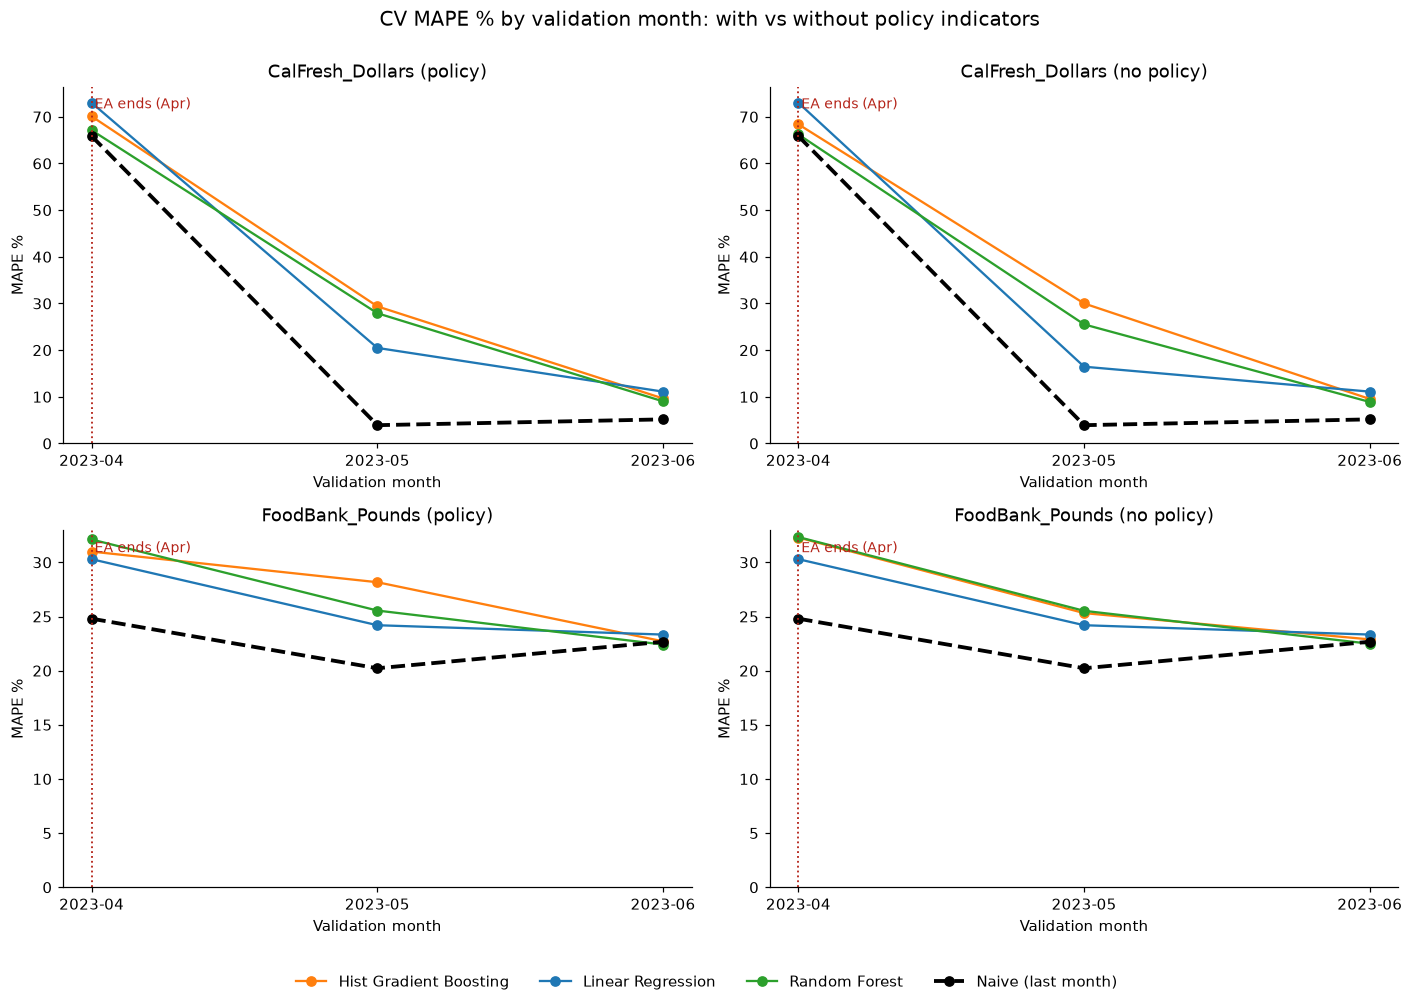

In [96]:
# Naive baseline per validation month: predict this month = last month
def naive_by_month(target):
    lag = HISTORY[target][0]
    x = data.dropna(subset=[target])
    if target == "FoodBank_Pounds":
        x = x[x["FoodBank_lag1_missing"] == 0]
    rows = []
    for m in sorted(fold_table["Val month"].unique()):
        g = x[x["Month_Year"] == m]
        a, p = np.log1p(g[target]), np.log1p(g[lag])
        rows.append({"Target": target, "Model": "Naive (last month)", "Version": "-", "Val month": m,
                     "Regime": regime(m),
                     "RMSE (log)": ((a - p) ** 2).mean() ** 0.5,
                     "MAE (log)": (a - p).abs().mean(),
                     "R2 (log)": r2_score(a, p),
                     "Bias (log)": (a - p).mean(),
                     "MAE (units)": (g[target] - g[lag]).abs().mean(),
                     "MAPE %": ((g[lag] - g[target]).abs() / g[target]).mean() * 100})
    return pd.DataFrame(rows)


fold_all = pd.concat([fold_table] + [naive_by_month(t) for t in TARGETS], ignore_index=True)

# Mean of each metric by regime (EA transition = 1 fold, Post-EA = average of 2 folds)
METRICS = ["RMSE (log)", "MAE (log)", "R2 (log)", "Bias (log)", "MAPE %"]
regime_table = (fold_all.groupby(["Target", "Model", "Version", "Regime"])[METRICS]
                .mean().round(3).reset_index())

for target in TARGETS:
    print(f"\n=== {target}: CV metrics by policy regime ===")
    print("Bias: + = under-predicts, - = over-predicts. EA transition = April fold; Post-EA = mean of May-June folds.")
    wide = (regime_table[regime_table["Target"] == target]
            .pivot_table(index=["Model", "Version"], columns="Regime", values=METRICS)
            .reindex(columns=METRICS, level=0)
            .reindex(columns=["EA transition", "Post-EA"], level=1))
    display(wide.round(3))


# Four panels per metric: one per target and policy version
MODEL_COLORS = {"Linear Regression": "#1f77b4", "Random Forest": "#2ca02c",
                "Hist Gradient Boosting": "#ff7f0e"}
PANELS = [(t, v) for t in TARGETS for v in ["With policy", "Without policy"]]


def plot_metric_panels(metric):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, (target, version) in zip(axes.flat, PANELS):
        sub = fold_all[fold_all["Target"] == target]
        models = sub[sub["Version"] == version]
        naive = sub[sub["Model"] == "Naive (last month)"].sort_values("Val month")

        # One line per model for this target and policy version
        for model, g in models.groupby("Model"):
            g = g.sort_values("Val month")
            ax.plot(g["Val month"], g[metric], marker="o", color=MODEL_COLORS[model], label=model)

        # Naive baseline in every panel as the reference line
        ax.plot(naive["Val month"], naive[metric], marker="o", color="black", lw=2.5, ls="--",
                label="Naive (last month)")

        ax.axvline("2023-04", color="#b42318", ls=":", lw=1.2)
        ax.text(0.05, 0.97, "EA ends (Apr)", color="#b42318", transform=ax.transAxes, va="top", fontsize=9)
        if metric.startswith("Bias"):
            ax.axhline(0, color="#888", lw=1)
        policy_label = "policy" if version == "With policy" else "no policy"
        ax.set_title(f"{target} ({policy_label})")
        ax.set_xlabel("Validation month")
        ax.set_ylabel(metric)

    # Same y-axis within each target, so the policy and no-policy panels are directly comparable
    for row in range(2):
        lo = min(axes[row, 0].get_ylim()[0], axes[row, 1].get_ylim()[0])
        hi = max(axes[row, 0].get_ylim()[1], axes[row, 1].get_ylim()[1])
        if not metric.startswith("Bias"):
            lo = 0
        for col in range(2):
            axes[row, col].set_ylim(lo, hi)

    # One shared legend below the four panels
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, fontsize=10)
    fig.suptitle(f"CV {metric} by validation month: with vs without policy indicators", fontsize=13, y=1.0)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()


plot_metric_panels("MAPE %")

**Perform Held Out Validation (July-August 2023)**

In [97]:
def naive_row(target):
    _, test, _ = make_split(target, False)
    lag = HISTORY[target][0]
    if target == "FoodBank_Pounds":
        test = test[test["FoodBank_lag1_missing"] == 0]
    pred, actual = test[lag], test[target]
    return {"Target": target, "Model": "Naive (last month)", "Version": "-",
            "Test RMSE": mean_squared_error(actual, pred) ** 0.5,
            "Test MAE": mean_absolute_error(actual, pred),
            "Test R2 (log)": r2_score(np.log1p(actual), np.log1p(pred)),
            "Test MAPE %": (np.abs(pred - actual) / actual).mean() * 100}


test_table = pd.concat([pd.DataFrame([r["test"] for r in runs.values()]),
                        pd.DataFrame([naive_row(t) for t in TARGETS])], ignore_index=True)
cols = ["Model", "Version", "Features", "CV RMSE (log)", "CV MAE (log)", "CV R2 (log)",
        "Test RMSE", "Test MAE", "Test R2 (log)", "Test MAPE %"]
for target in TARGETS:
    print(f"\n=== {target}: held-out test results (sorted by Test MAPE) ===")
    display(test_table[test_table["Target"] == target][cols].sort_values("Test MAPE %").round(3))

# Best trained model per target, chosen by CV RMSE (not by test results)
best_keys = {}
for target in TARGETS:
    cands = {k: r for k, r in runs.items() if k[0] == target}
    best_keys[target] = min(cands, key=lambda k: cands[k]["test"]["CV RMSE (log)"])
    print(f"Best by CV for {target}: {best_keys[target][1]} ({'with' if best_keys[target][2] else 'without'} policy)")


=== CalFresh_Dollars: held-out test results (sorted by Test MAPE) ===


,Model,Version,Features,CV RMSE (log),CV MAE (log),CV R2 (log),Test RMSE,Test MAE,Test R2 (log),Test MAPE %
12,Naive (last month),-,NaN,NaN,NaN,NaN,18357.509,12007.476,0.998,3.436
4,Hist Gradient Boosting,Without policy,14.0,0.361,0.320,0.941,40628.583,23683.260,0.994,5.837
3,Random Forest,With policy,16.0,0.341,0.305,0.947,55284.478,31407.619,0.994,7.037
2,Random Forest,Without policy,14.0,0.330,0.287,0.950,54318.342,31017.257,0.993,7.249
5,Hist Gradient Boosting,With policy,16.0,0.361,0.319,0.940,47461.760,27352.763,0.992,7.307
1,Linear Regression,With policy,16.0,0.515,0.316,0.881,239367.657,127548.892,0.978,18.241
0,Linear Regression,Without policy,14.0,0.500,0.300,0.884,239367.657,127548.892,0.978,18.241



=== FoodBank_Pounds: held-out test results (sorted by Test MAPE) ===


,Model,Version,Features,CV RMSE (log),CV MAE (log),CV R2 (log),Test RMSE,Test MAE,Test R2 (log),Test MAPE %
13,Naive (last month),-,NaN,NaN,NaN,NaN,24365.917,13228.118,0.958,20.526
6,Linear Regression,Without policy,15.0,0.314,0.237,0.963,25845.997,13481.457,0.957,20.812
7,Linear Regression,With policy,17.0,0.314,0.237,0.963,25845.997,13481.457,0.957,20.812
9,Random Forest,With policy,17.0,0.318,0.243,0.962,31722.049,14422.941,0.953,20.986
8,Random Forest,Without policy,15.0,0.318,0.243,0.961,31448.992,14380.201,0.953,21.009
11,Hist Gradient Boosting,With policy,17.0,0.335,0.255,0.957,30930.948,14843.418,0.949,22.801
10,Hist Gradient Boosting,Without policy,15.0,0.330,0.249,0.959,32104.791,15029.806,0.946,23.229


Best by CV for CalFresh_Dollars: Random Forest (without policy)
Best by CV for FoodBank_Pounds: Linear Regression (without policy)


**Best Performing Model By Policy Version**

In [98]:
best_rows = []
naive_lookup = {r["Target"]: r for r in [naive_row(t) for t in TARGETS]}
for target in TARGETS:
    for with_policy in (False, True):
        cands = {k: r for k, r in runs.items() if k[0] == target and k[2] == with_policy}
        k = min(cands, key=lambda key: cands[key]["test"]["CV RMSE (log)"])
        t = cands[k]["test"]
        naive = naive_lookup[target]
        best_rows.append({
            "Target": target, "Version": "With policy" if with_policy else "Without policy",
            "Best model": k[1],
            "CV RMSE (log)": t["CV RMSE (log)"], "CV MAE (log)": t["CV MAE (log)"], "CV R2 (log)": t["CV R2 (log)"],
            "Test RMSE": t["Test RMSE"], "Test MAE": t["Test MAE"], "Test R2 (log)": t["Test R2 (log)"],
            "Test MAPE %": t["Test MAPE %"],
            "Naive Test MAPE %": naive["Test MAPE %"],
            "Beats naive?": "Yes" if t["Test MAPE %"] < naive["Test MAPE %"] else "No",
        })
best_table = pd.DataFrame(best_rows)

for version in ["Without policy", "With policy"]:
    print(f"\n=== Best-performing model per target: {version.lower()} indicators ===")
    display(best_table[best_table["Version"] == version].drop(columns="Version").round(3).reset_index(drop=True))


=== Best-performing model per target: without policy indicators ===


,Target,Best model,CV RMSE (log),CV MAE (log),CV R2 (log),Test RMSE,Test MAE,Test R2 (log),Test MAPE %,Naive Test MAPE %,Beats naive?
0,CalFresh_Dollars,Random Forest,0.330,0.287,0.950,54318.342,31017.257,0.993,7.249,3.436,No
1,FoodBank_Pounds,Linear Regression,0.314,0.237,0.963,25845.997,13481.457,0.957,20.812,20.526,No



=== Best-performing model per target: with policy indicators ===


,Target,Best model,CV RMSE (log),CV MAE (log),CV R2 (log),Test RMSE,Test MAE,Test R2 (log),Test MAPE %,Naive Test MAPE %,Beats naive?
0,CalFresh_Dollars,Random Forest,0.341,0.305,0.947,55284.478,31407.619,0.994,7.037,3.436,No
1,FoodBank_Pounds,Linear Regression,0.314,0.237,0.963,25845.997,13481.457,0.957,20.812,20.526,No


**Output Prediction Intervals (90%)**

In [99]:
interval_rows = []
for key, r in runs.items():
    q = np.quantile(np.abs(r["oof"]["resid_log"]), 0.90)
    tp = r["test_pred"]
    tp["lower"] = np.expm1(tp["pred_log"] - q)
    tp["upper"] = np.expm1(tp["pred_log"] + q)
    covered = ((tp["actual"] >= tp["lower"]) & (tp["actual"] <= tp["upper"])).mean()
    interval_rows.append({"Target": key[0], "Model": key[1], "Version": "With policy" if key[2] else "Without policy",
                          "Half-width (log)": q, "Typical range": f"x{np.exp(-q):.2f} to x{np.exp(q):.2f}",
                          "Test coverage": covered})
interval_table = pd.DataFrame(interval_rows)
display(interval_table.round(3))

,Target,Model,Version,Half-width (log),Typical range,Test coverage
0,CalFresh_Dollars,Linear Regression,Without policy,0.568,x0.57 to x1.76,0.995
1,CalFresh_Dollars,Linear Regression,With policy,0.568,x0.57 to x1.76,0.995
2,CalFresh_Dollars,Random Forest,Without policy,0.554,x0.57 to x1.74,0.995
3,CalFresh_Dollars,Random Forest,With policy,0.554,x0.57 to x1.74,0.995
4,CalFresh_Dollars,Hist Gradient Boosting,Without policy,0.548,x0.58 to x1.73,0.995
5,CalFresh_Dollars,Hist Gradient Boosting,With policy,0.589,x0.55 to x1.80,0.985
6,FoodBank_Pounds,Linear Regression,Without policy,0.485,x0.62 to x1.62,0.925
7,FoodBank_Pounds,Linear Regression,With policy,0.485,x0.62 to x1.62,0.925
8,FoodBank_Pounds,Random Forest,Without policy,0.513,x0.60 to x1.67,0.906
9,FoodBank_Pounds,Random Forest,With policy,0.506,x0.60 to x1.66,0.906


**Return Actual vs Predicted Visualizations for CalFresh Dollars and FoodBank Pounds**

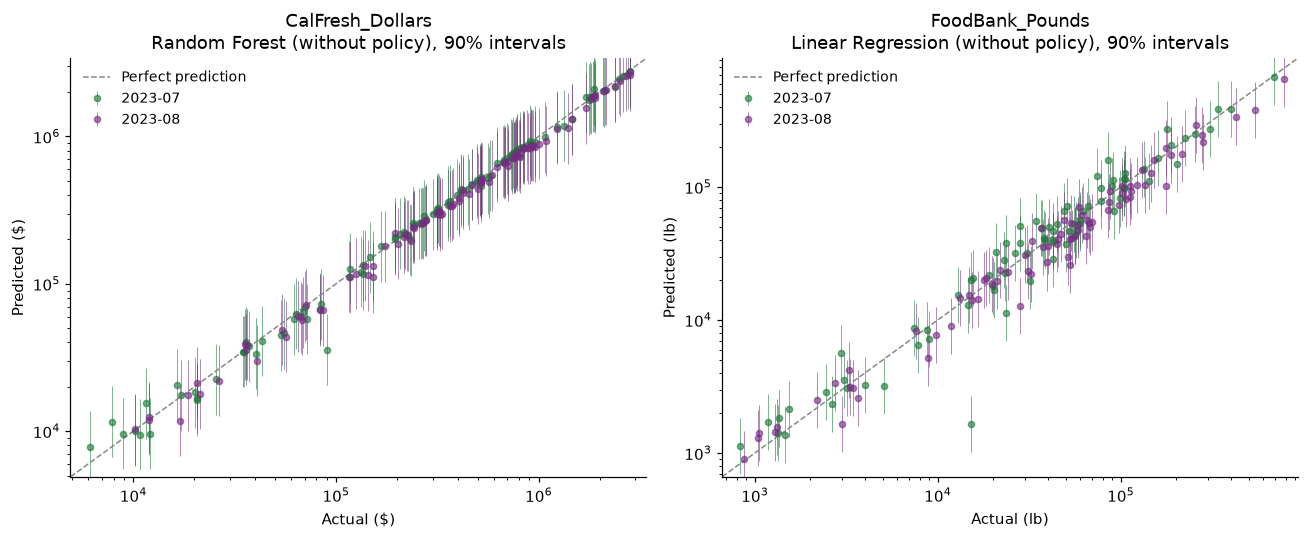

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target in zip(axes, TARGETS):
    key = best_keys[target]
    tp = runs[key]["test_pred"]
    for month, color in zip(sorted(tp["Month_Year"].unique()), ["#1b7837", "#762a83"]):
        g = tp[tp["Month_Year"] == month]
        ax.errorbar(g["actual"], g["pred"], yerr=[g["pred"] - g["lower"], g["upper"] - g["pred"]],
                    fmt="o", ms=4, alpha=0.6, elinewidth=0.6, color=color, label=month)
    lim = [tp[["actual", "pred"]].min().min() * 0.8, tp[["actual", "pred"]].max().max() * 1.2]
    ax.plot(lim, lim, color="#888", ls="--", lw=1, label="Perfect prediction")
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
           xlabel=f"Actual ({UNITS[target]})", ylabel=f"Predicted ({UNITS[target]})",
           title=f"{target}\n{key[1]} ({'with' if key[2] else 'without'} policy), 90% intervals")
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Time Series: Predictions vs actuals with policy events**

**What the lines show.** One panel per target, using the best model by CV for that target. Each point is the **county total** for a month (all zip codes added together):

| Line | What it is |
|---|---|
| **Black solid (Actual)** | The real county total each month, February–August |
| **Blue dashed (CV prediction, out-of-fold)** | April–June predictions from the cross-validation folds. Each month is predicted by a model trained only on *earlier* months, so it shows how the model would have done in real time. February–March have no blue points because they are only ever used for training. |
| **Red solid (Test prediction)** | July–August predictions from the final model, which never saw these months |
| **Red shaded band** | The 90% prediction intervals for July–August, added up across zips. Summing zip-level ranges makes the band wider than a true county-level interval, so read it as a cautious upper bound. |
| **Red dotted vertical lines** | Policy events: Emergency Allotments end (April) and ABAWD work rules resume (July) |
| **Grey background** | The held-out test period |

**What to look for:** how far the blue and red lines sit from the black line, especially right after each policy event.

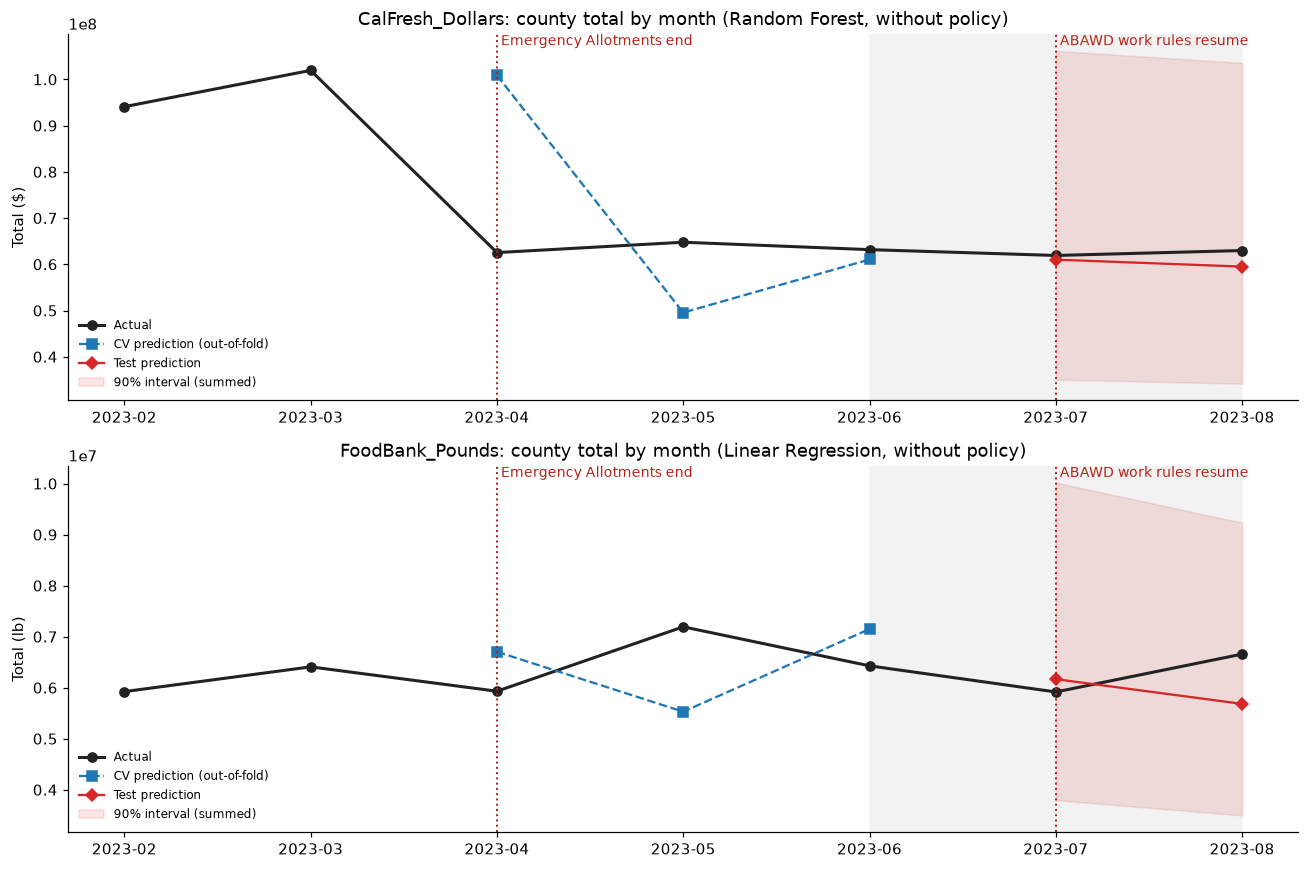

In [101]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, target in zip(axes, TARGETS):
    key = best_keys[target]
    r = runs[key]
    train, _, _ = make_split(target, key[2])
    actual_all = pd.concat([train[["Month_Year", target]].rename(columns={target: "actual"}),
                            r["test_pred"][["Month_Year", "actual"]]])
    actual_m = actual_all.groupby("Month_Year")["actual"].sum()
    oof_m = r["oof"].groupby("Month_Year")["pred"].sum()
    test_m = r["test_pred"].groupby("Month_Year")[["pred", "lower", "upper"]].sum()

    ax.plot(actual_m.index, actual_m.values, "o-", color="#222", lw=2, label="Actual")
    ax.plot(oof_m.index, oof_m.values, "s--", color="#1f77b4", label="CV prediction (out-of-fold)")
    ax.plot(test_m.index, test_m["pred"], "D-", color="#d62728", label="Test prediction")
    ax.fill_between(test_m.index, test_m["lower"], test_m["upper"], color="#d62728", alpha=0.12,
                    label="90% interval (summed)")
    ax.axvspan(TRAIN_END, actual_m.index[-1], color="#f2f2f2", zorder=0)
    for month, label in POLICY_EVENTS.items():
        ax.axvline(month, color="#b42318", ls=":", lw=1.3)
        ax.text(month, ax.get_ylim()[1], f" {label}", color="#b42318", va="top", fontsize=9)
    ax.set_title(f"{target}: county total by month ({key[1]}, {'with' if key[2] else 'without'} policy)")
    ax.set_ylabel(f"Total ({UNITS[target]})")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

**Residuals around polict change dates**


=== CalFresh_Dollars: mean residual (bias) and mean |residual| by month ===


Month_Year                             2023-04  2023-05  2023-06  2023-07  2023-08
Model                  Version                                                    
Hist Gradient Boosting With policy      -0.491    0.321   -0.010   -0.010    0.014
                       Without policy   -0.515    0.325   -0.011   -0.002    0.019
Linear Regression      With policy      -0.538    0.221    0.152    0.018    0.087
                       Without policy   -0.538    0.165    0.152    0.018    0.087
Random Forest          With policy      -0.508    0.274    0.041    0.028    0.073
                       Without policy   -0.502    0.210    0.025    0.025    0.069


=== FoodBank_Pounds: mean residual (bias) and mean |residual| by month ===


Month_Year                             2023-04  2023-05  2023-06  2023-07  2023-08
Model                  Version                                                    
Hist Gradient Boosting With policy      -0.156    0.173   -0.054   -0.036    0.100
                       Without policy   -0.164    0.163   -0.055   -0.045    0.118
Linear Regression      With policy      -0.168    0.133   -0.061   -0.027    0.123
                       Without policy   -0.168    0.133   -0.061   -0.027    0.123
Random Forest          With policy      -0.139    0.106   -0.044   -0.026    0.118
                       Without policy   -0.139    0.103   -0.045   -0.029    0.118

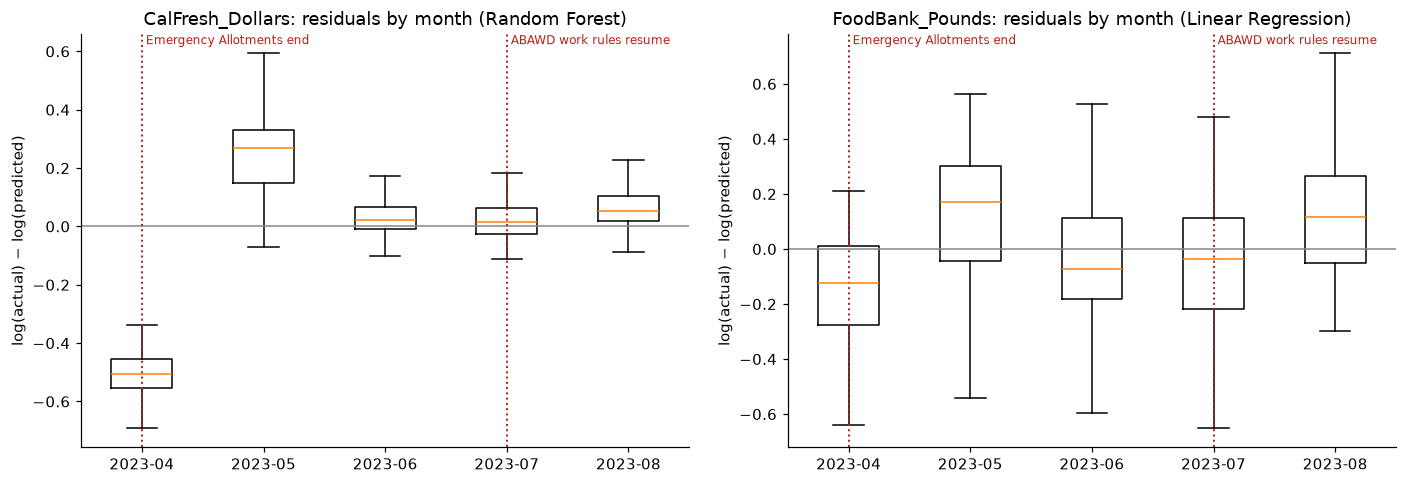

In [102]:
resid_rows = []
for key, r in runs.items():
    both = pd.concat([r["oof"].assign(Source="CV"), r["test_pred"].assign(Source="Test")], ignore_index=True)
    both = both.assign(Target=key[0], Model=key[1], Version="With policy" if key[2] else "Without policy")
    resid_rows.append(both)
resid = pd.concat(resid_rows, ignore_index=True)
resid["Regime"] = resid["Month_Year"].map(regime)

summary = (resid.groupby(["Target", "Model", "Version", "Month_Year"])["resid_log"]
           .agg(mean_bias="mean", abs_error=lambda s: s.abs().mean()).round(3).reset_index())
for target in TARGETS:
    print(f"\n=== {target}: mean residual (bias) and mean |residual| by month ===")
    display(summary[summary["Target"] == target].pivot_table(index=["Model", "Version"], columns="Month_Year",
                                                             values="mean_bias").round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, target in zip(axes, TARGETS):
    key = best_keys[target]
    sub = resid[(resid["Target"] == target) & (resid["Model"] == key[1]) &
                (resid["Version"] == ("With policy" if key[2] else "Without policy"))]
    months = sorted(sub["Month_Year"].unique())
    ax.boxplot([sub.loc[sub["Month_Year"] == m, "resid_log"] for m in months], showfliers=False)
    ax.set_xticks(range(1, len(months) + 1), months)
    ax.axhline(0, color="#888", lw=1)
    for month, label in POLICY_EVENTS.items():
        if month in months:
            i = months.index(month) + 1
            ax.axvline(i, color="#b42318", ls=":", lw=1.3)
            ax.text(i, ax.get_ylim()[1], f" {label}", color="#b42318", va="top", fontsize=8)
    ax.set_title(f"{target}: residuals by month ({key[1]})")
    ax.set_ylabel("log(actual) − log(predicted)")
plt.tight_layout()
plt.show()

**Feature Importance and Policy Sensitivity**

**Permutation importance** measures how much a model's test error (log-RMSE) rises when one feature's values are shuffled. Bigger means the model relies on it more; values near 0, or negative, mean the feature isn't helping.

How to read the tables:
- One table per target and tree model.
- Rows are the top 8 features in the no-policy model, plus the two policy features at the bottom.
- **Rank change with policy** shows whether a feature moved up or down once policy indicators were added. "new (policy feature)" marks features that only exist in the policy version.
- Last month's value (`CalFresh_lag1` / `FoodBank_lag1`) is always rank 1, with importance about 100 times larger than anything else. The other rows show what the models use *beyond* last month's value.

In [103]:
imp_rows = []
for key, r in runs.items():
    target, model_name, with_policy = key
    if model_name == "Linear Regression":
        continue
    imp = permutation_importance(r["best"], r["X_test"], r["y_test"], n_repeats=15, random_state=42,
                                 scoring="neg_root_mean_squared_error")
    for f, v in zip(r["X_test"].columns, imp.importances_mean):
        imp_rows.append({"Target": target, "Model": model_name,
                         "Version": "With policy" if with_policy else "Without policy", "Feature": f, "Importance": v})
importance = pd.DataFrame(imp_rows)


def rank_change(row):
    if pd.isna(row["Rank (no policy)"]):
        return "new (policy feature)"
    diff = int(row["Rank (no policy)"] - row["Rank (policy)"])
    return "same" if diff == 0 else (f"up {diff}" if diff > 0 else f"down {-diff}")


def importance_table(target, model_name, top_n=8):
    sub = importance[(importance["Target"] == target) & (importance["Model"] == model_name)]
    wide = sub.pivot_table(index="Feature", columns="Version", values="Importance")
    t = pd.DataFrame({
        "Importance (no policy)": wide["Without policy"],
        "Rank (no policy)": wide["Without policy"].rank(ascending=False, method="min"),
        "Importance (policy)": wide["With policy"],
        "Rank (policy)": wide["With policy"].rank(ascending=False, method="min"),
    })
    t["Rank change with policy"] = t.apply(rank_change, axis=1)
    # Top features without policy, plus the policy features so their effect is always visible
    keep = list(t.sort_values("Rank (no policy)").head(top_n).index) + [f for f in POLICY if f in t.index]
    t = t.loc[keep].reset_index()
    for c in ["Rank (no policy)", "Rank (policy)"]:
        t[c] = t[c].map(lambda v: "-" if pd.isna(v) else int(v))
    for c in ["Importance (no policy)", "Importance (policy)"]:
        t[c] = t[c].map(lambda v: "-" if pd.isna(v) else f"{v:.4f}")
    return t


for target in TARGETS:
    for model_name in ["Random Forest", "Hist Gradient Boosting"]:
        print(f"\n=== {target} | {model_name}: top {8} features + policy features ===")
        display(importance_table(target, model_name))


=== CalFresh_Dollars | Random Forest: top 8 features + policy features ===


,Feature,Importance (no policy),Rank (no policy),Importance (policy),Rank (policy),Rank change with policy
0,CalFresh_lag1,1.7022,1,1.7758,1,same
1,LIHEAP_lag1,0.0333,2,0.0228,2,same
2,Log_Households,0.0214,3,0.0223,3,same
3,LIHEAPxPoverty,0.0206,4,0.0204,4,same
4,Demo_Imputed,0.0152,5,0.0061,7,down 2
5,Unemployment_Rate,0.0107,6,0.0125,5,up 1
6,LIHEAP_lag1_per_1k_HH,0.0091,7,0.0084,6,up 1
7,Poverty_Rate,0.0044,8,0.0053,8,same
8,Policy_Period_EA_Ended,-,-,0.0000,13,new (policy feature)
9,LIHEAPxEA_Ended,-,-,-0.0014,16,new (policy feature)



=== CalFresh_Dollars | Hist Gradient Boosting: top 8 features + policy features ===


,Feature,Importance (no policy),Rank (no policy),Importance (policy),Rank (policy),Rank change with policy
0,CalFresh_lag1,2.0262,1,2.0199,1,same
1,LIHEAP_lag2,0.0017,2,-0.0008,14,down 12
2,CalFresh_yoy_change_lag1,0.0009,3,0.0229,2,up 1
3,LIHEAP_lag3,0.0007,4,-0.0063,16,down 12
4,LIHEAPxRent,0.0004,5,-0.0000,11,down 6
5,Poverty_Rate,0.0001,6,0.0010,7,down 1
6,Pct_65_Plus,0.0000,7,0.0003,9,down 2
7,Unemployment_Rate,-0.0005,8,-0.0001,12,down 4
8,Policy_Period_EA_Ended,-,-,0.0000,10,new (policy feature)
9,LIHEAPxEA_Ended,-,-,0.0021,4,new (policy feature)



=== FoodBank_Pounds | Random Forest: top 8 features + policy features ===


,Feature,Importance (no policy),Rank (no policy),Importance (policy),Rank (policy),Rank change with policy
0,FoodBank_lag1,1.7860,1,1.7846,1,same
1,Unemployment_Rate,0.0069,2,0.0072,2,same
2,Median_Rent_k,0.0064,3,0.0069,3,same
3,Log_Households,0.0035,4,0.0037,4,same
4,FoodBank_yoy_change_lag1,0.0028,5,0.0023,5,same
5,Poverty_Rate,0.0016,6,0.0014,6,same
6,LIHEAPxRent,0.0014,7,0.0012,7,same
7,Pct_65_Plus,0.0010,8,0.0010,8,same
8,Policy_Period_EA_Ended,-,-,-0.0000,15,new (policy feature)
9,LIHEAPxEA_Ended,-,-,-0.0006,16,new (policy feature)



=== FoodBank_Pounds | Hist Gradient Boosting: top 8 features + policy features ===


,Feature,Importance (no policy),Rank (no policy),Importance (policy),Rank (policy),Rank change with policy
0,FoodBank_lag1,1.7539,1,1.7683,1,same
1,FoodBank_yoy_change_lag1,0.0059,2,0.0055,3,down 1
2,Log_Households,0.0035,3,0.0027,5,down 2
3,Unemployment_Rate,0.0035,4,0.0066,2,up 2
4,Pct_Single_Parent_HH,0.0024,5,0.0008,7,down 2
5,Median_Rent_k,0.0021,6,0.0029,4,up 2
6,LIHEAPxRent,0.0009,7,0.0005,9,down 2
7,Pct_65_Plus,0.0008,8,0.0003,10,down 2
8,Policy_Period_EA_Ended,-,-,0.0000,12,new (policy feature)
9,LIHEAPxEA_Ended,-,-,-0.0009,17,new (policy feature)


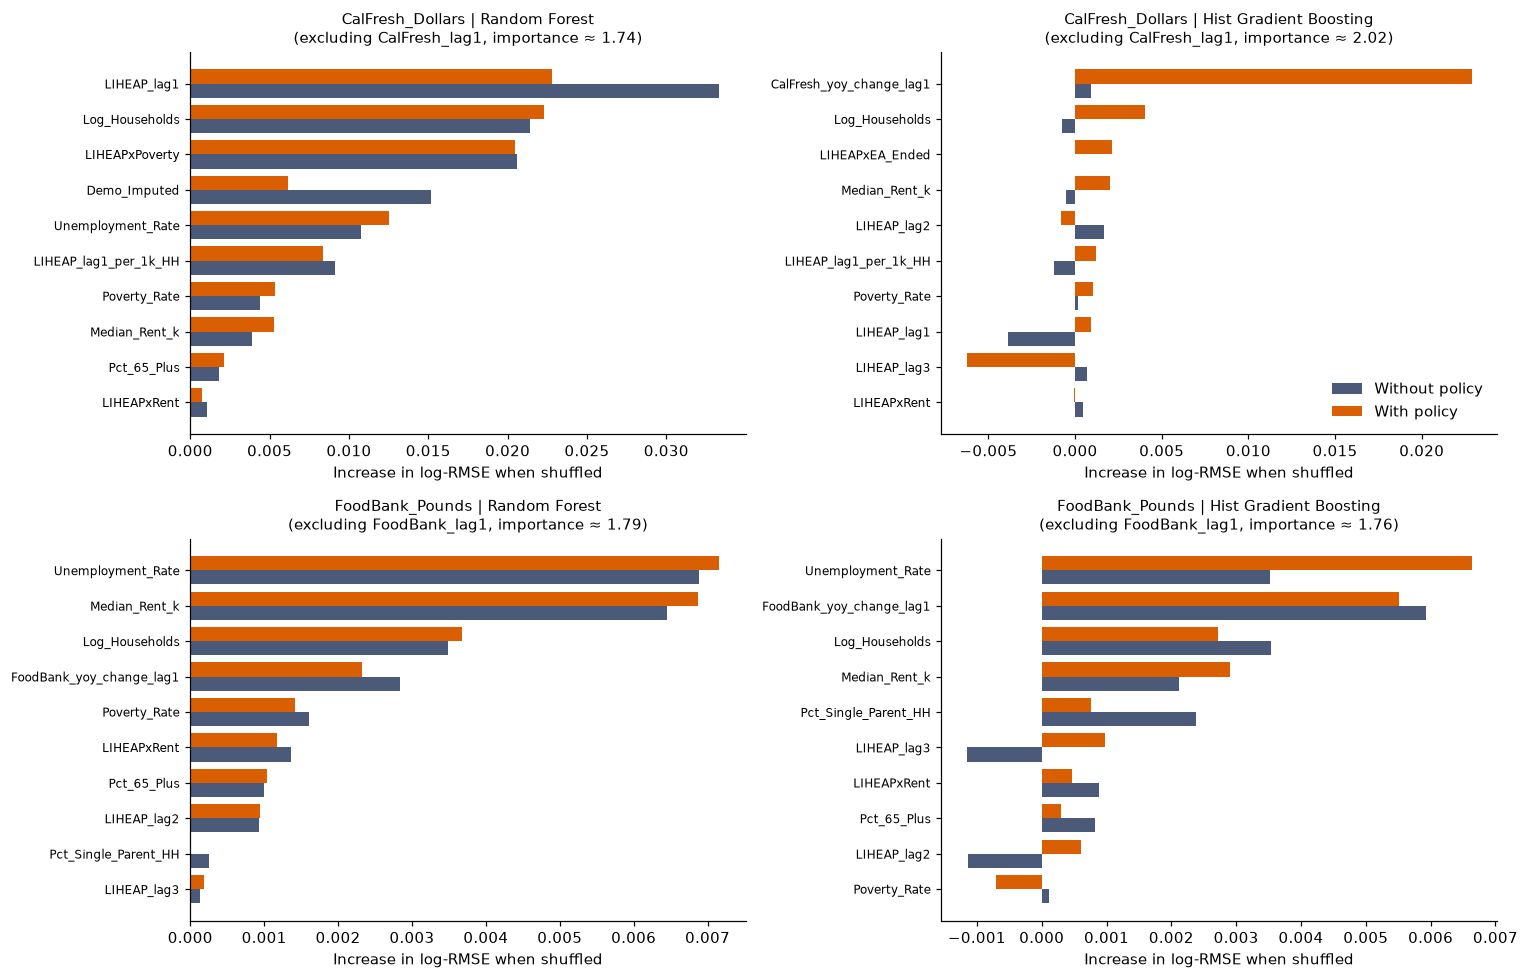

In [104]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, target in enumerate(TARGETS):
    for col, model_name in enumerate(["Random Forest", "Hist Gradient Boosting"]):
        ax = axes[row, col]
        sub = importance[(importance["Target"] == target) & (importance["Model"] == model_name)]
        wide = sub.pivot_table(index="Feature", columns="Version", values="Importance").fillna(0)
        lag = HISTORY[target][0]
        wide = wide.drop(index=lag)                       # shown separately: it dwarfs everything else
        wide = wide.loc[wide.max(axis=1).sort_values(ascending=True).index[-10:]]
        y = np.arange(len(wide))
        ax.barh(y - 0.2, wide.get("Without policy", 0), height=0.4, label="Without policy", color="#4a5a78")
        ax.barh(y + 0.2, wide.get("With policy", 0), height=0.4, label="With policy", color="#d95f02")
        ax.set_yticks(y, wide.index, fontsize=8)
        lag_imp = sub[sub["Feature"] == lag]["Importance"].mean()
        ax.set_title(f"{target} | {model_name}\n(excluding {lag}, importance ≈ {lag_imp:.2f})", fontsize=10)
        ax.set_xlabel("Increase in log-RMSE when shuffled")
axes[0, 1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Do Policy Indicators Improve Accuracy? (overall and during the transition)**

In [105]:
pairs = []
for target in TARGETS:
    for model_name in MODEL_SPECS:
        a, b = runs[(target, model_name, False)], runs[(target, model_name, True)]
        fa, fb = a["folds"].set_index("Val month"), b["folds"].set_index("Val month")
        pairs.append({
            "Target": target, "Model": model_name,
            "CV RMSE: no policy": a["test"]["CV RMSE (log)"], "CV RMSE: policy": b["test"]["CV RMSE (log)"],
            "Apr (transition) MAPE: no policy": fa.loc["2023-04", "MAPE %"],
            "Apr (transition) MAPE: policy": fb.loc["2023-04", "MAPE %"],
            "Test MAPE: no policy": a["test"]["Test MAPE %"], "Test MAPE: policy": b["test"]["Test MAPE %"],
        })
policy_effect = pd.DataFrame(pairs)
policy_effect["Test MAPE change (pts)"] = policy_effect["Test MAPE: policy"] - policy_effect["Test MAPE: no policy"]
policy_effect["Policy helps on test?"] = np.where(policy_effect["Test MAPE change (pts)"] < -0.5, "Yes",
                                                  np.where(policy_effect["Test MAPE change (pts)"] > 0.5, "Worse", "No difference"))
display(policy_effect.round(2))

,Target,Model,CV RMSE: no policy,CV RMSE: policy,Apr (transition) MAPE: no policy,Apr (transition) MAPE: policy,Test MAPE: no policy,Test MAPE: policy,Test MAPE change (pts),Policy helps on test?
0,CalFresh_Dollars,Linear Regression,0.50,0.52,73.00,73.00,18.24,18.24,0.00,No difference
1,CalFresh_Dollars,Random Forest,0.33,0.34,66.21,67.11,7.25,7.04,-0.21,No difference
2,CalFresh_Dollars,Hist Gradient Boosting,0.36,0.36,68.39,70.10,5.84,7.31,1.47,Worse
3,FoodBank_Pounds,Linear Regression,0.31,0.31,30.29,30.29,20.81,20.81,0.00,No difference
4,FoodBank_Pounds,Random Forest,0.32,0.32,32.34,32.11,21.01,20.99,-0.02,No difference
5,FoodBank_Pounds,Hist Gradient Boosting,0.33,0.33,32.29,30.99,23.23,22.80,-0.43,No difference


**Model Specifications and Chosen Parameters**

In [106]:
spec_rows = []
for key, r in runs.items():
    target, model_name, with_policy = key
    spec = MODEL_SPECS[model_name]
    params = r["test"]["Best params"]
    spec_rows.append({
        "Target": target, "Model": model_name, "Version": "With policy" if with_policy else "Without policy",
        "Search": "Grid" if spec["search"] == "grid" else f"Random ({spec['n_iter']} draws)",
        "n features": len(r["features"]),
        "Selection metric": "CV RMSE (log)",
        "CV RMSE (log)": round(r["test"]["CV RMSE (log)"], 3),
        "Test MAPE %": round(r["test"]["Test MAPE %"], 2),
        "Chosen settings": ", ".join(f"{k}={v}" for k, v in params.items()),
    })
spec_table = pd.DataFrame(spec_rows)

print("All models: tuned with expanding-window CV (3 monthly folds); settings chosen by lowest CV RMSE (log).")
print("Test MAPE % is reported for the held-out July-August months.")
for target in TARGETS:
    print(f"\n=== {target} ===")
    display(spec_table[spec_table["Target"] == target].drop(columns="Target").reset_index(drop=True))

All models: tuned with expanding-window CV (3 monthly folds); settings chosen by lowest CV RMSE (log).
Test MAPE % is reported for the held-out July-August months.

=== CalFresh_Dollars ===


,Model,Version,Search,n features,Selection metric,CV RMSE (log),Test MAPE %,Chosen settings
0,Linear Regression,Without policy,Grid,14,CV RMSE (log),0.500,18.24,"model=Lasso, alpha=0.1"
1,Linear Regression,With policy,Grid,16,CV RMSE (log),0.515,18.24,"model=Lasso, alpha=0.1"
2,Random Forest,Without policy,Random (25 draws),14,CV RMSE (log),0.330,7.25,"n_estimators=600, min_samples_leaf=1, max_samples=0.7, max_features=0.7, max_depth=None"
3,Random Forest,With policy,Random (25 draws),16,CV RMSE (log),0.341,7.04,"n_estimators=300, min_samples_leaf=1, max_samples=0.7, max_features=0.7, max_depth=8"
4,Hist Gradient Boosting,Without policy,Random (40 draws),14,CV RMSE (log),0.361,5.84,"min_samples_leaf=10, max_leaf_nodes=31, max_iter=800, max_depth=5, loss=squared_error, learning_rate=0.02, l2_regula..."
5,Hist Gradient Boosting,With policy,Random (40 draws),16,CV RMSE (log),0.361,7.31,"min_samples_leaf=20, max_leaf_nodes=15, max_iter=800, max_depth=None, loss=squared_error, learning_rate=0.1, l2_regu..."



=== FoodBank_Pounds ===


,Model,Version,Search,n features,Selection metric,CV RMSE (log),Test MAPE %,Chosen settings
0,Linear Regression,Without policy,Grid,15,CV RMSE (log),0.314,20.81,"model=LinearRegression, fit_intercept=True, positive=True"
1,Linear Regression,With policy,Grid,17,CV RMSE (log),0.314,20.81,"model=LinearRegression, fit_intercept=True, positive=True"
2,Random Forest,Without policy,Random (25 draws),15,CV RMSE (log),0.318,21.01,"n_estimators=300, min_samples_leaf=3, max_samples=0.7, max_features=1.0, max_depth=10"
3,Random Forest,With policy,Random (25 draws),17,CV RMSE (log),0.318,20.99,"n_estimators=300, min_samples_leaf=3, max_samples=0.7, max_features=1.0, max_depth=10"
4,Hist Gradient Boosting,Without policy,Random (40 draws),15,CV RMSE (log),0.330,23.23,"min_samples_leaf=10, max_leaf_nodes=15, max_iter=400, max_depth=None, loss=absolute_error, learning_rate=0.05, l2_re..."
5,Hist Gradient Boosting,With policy,Random (40 draws),17,CV RMSE (log),0.335,22.80,"min_samples_leaf=10, max_leaf_nodes=7, max_iter=800, max_depth=None, loss=absolute_error, learning_rate=0.02, l2_reg..."


## Conclusions: LIHEAP/CalFresh → CalFresh Dollars

**Best model.** Chosen by CV RMSE, without looking at the test months: **random forest** in both versions.

| | Without policy | With policy |
|---|---|---|
| CV RMSE (log) | 0.330 | 0.341 |
| Test MAE | $31,017 | $31,408 |
| Test MAPE | 7.2% | 7.0% |

Gradient boosting had the lowest test error (5.8% without policy), but it ranked lower on CV, so it was not selected. Choosing by test results would overstate performance.

**The naive forecast beats every model.** Predicting each zip's CalFresh as last month's value gives **3.4% MAPE ($12,007 MAE)**, about half the error of the best model. CalFresh changes very little from month to month, and the models add error by pulling each zip toward similar zips instead of keeping its exact level.

**Policy indicators do not improve accuracy.**
- Random forest: test MAPE changed by −0.2 points.
- Linear regression: identical results, because the tuned Lasso set both policy coefficients to zero.
- Gradient boosting: worse, by +1.5 points.
- Both policy features have importance at or below zero in every tree model.

**Policy transitions are where every model fails.**
- **April 2023 (Emergency Allotments end):** CV MAPE was 66–73% for all models, the same as the naive forecast (66%). Every model over-predicted by about 40% (bias ≈ −0.50 log). CalFresh fell sharply overnight, and nothing trained on earlier months could anticipate it.
- **May:** the models over-corrected and under-predicted (bias +0.17 to +0.33), while the naive forecast was nearly unbiased.
- **July (ABAWD work rules resume):** test residuals were close to zero (+0.02 to +0.03), so no visible effect on CalFresh in that month.

**What the models use.** Last month's CalFresh dominates (importance ≈ 1.7–2.0). Next come `LIHEAP_lag1` (0.033 in random forest), zip size (`Log_Households`) and `LIHEAPxPoverty`. LIHEAP carries a small signal, mostly about *which* zips have higher CalFresh, not *when* it changes.

**Uncertainty.** The 90% intervals run from about 0.57x to 1.74x the prediction, and they covered 99.5% of test values. They are wider than needed, because April's large CV errors stretch them.



## Conclusions: LIHEAP/Food Bank → Food Bank Pounds

**Best model.** Chosen by CV RMSE: **linear regression** in both versions. The tuned model is ordinary least squares with all coefficients constrained to be positive.

| | Without policy | With policy |
|---|---|---|
| CV RMSE (log) | 0.314 | 0.314 |
| Test MAE | 13,481 lb | 13,481 lb |
| Test MAPE | 20.8% | 20.8% |

**No model beats the naive forecast.** Last month's pounds gives **20.5% MAPE (13,228 lb MAE)**. All trained models fall between 20.8% and 23.2%. Food bank deliveries swing about 20% from month to month in ways these features cannot explain.

**Policy indicators do not improve accuracy.**
- Linear regression: identical results; the positive-coefficient constraint dropped the policy features.
- Random forest: −0.02 points.
- Gradient boosting: −0.4 points.

None of these changes is meaningful.

**Policy transition.** April's CV MAPE was 30–32%, versus 24% after the transition. The naive forecast was 25% in April. The Emergency Allotment ending affected food bank distribution far less than CalFresh: bias was about −0.15 log, compared with −0.50 for CalFresh.

**What the models use.** Last month's pounds dominates (importance ≈ 1.8). Among the rest:
- **Context features rank highest:** unemployment rate, median rent, zip size and the year-over-year trend.
- **LIHEAP features add almost nothing:** importance ≤ 0.001.

LIHEAP enrollment does not help predict month-to-month food bank distribution.

**Uncertainty.** The 90% intervals run from about 0.60x to 1.67x the prediction, with **91–93% test coverage**. They are well calibrated, so they can be trusted for planning ranges.


## Do Policy Indicators Improve Accuracy? Recommendations for Future Policy Changes

**Answer: no.** Across 6 model comparisons (3 model types × 2 targets), adding the Emergency Allotment indicators never improved test MAPE by more than 0.5 points, and it made one model worse.

The indicators can't help in principle with this data:
- The policy change happened once, in April, so the "after" flag is the same in every test month.
- In the transition fold, the training months (February–March) contain no "after" examples at all.

A yes/no policy flag cannot teach a model the size of a change it has never seen.

**Recommendations for using these models during future policy changes**

1. **Default to the naive forecast for one-month-ahead planning.** It was the most accurate method for both targets. Use the trained models for understanding *which zip codes* have higher need, not for month-to-month forecasting.
2. **Expect the transition month to be missed.** When a known policy change takes effect, no model trained on earlier months will capture it. In April 2023, every forecast missed CalFresh by about 40%. Adjust the forecast by hand using the announced change, for example by applying the expected benefit reduction to last month's value.
3. **Retrain after the change.** Once one or two months of post-change data exist, retrain on post-change months only, or weight them more heavily. In May 2023, mixing pre- and post-change months caused models to over-correct.
4. **Encode the size of a policy change, not just its timing.** A feature such as "expected % change in benefits" is more informative than a 0/1 flag, especially when only one or two policy events are available.
5. **Monitor bias every month.** If the average log residual moves beyond ±0.10 (about a 10% systematic error), treat it as a sign of a regime change and retrain.
6. **Expand the data before revisiting the policy question.** Zip-level LIHEAP data currently covers only January–July 2023, with one policy change inside the training window. More months, and several policy events with data before and after each, are needed to measure policy effects reliably.
